# CA1 – Numeric Variables
**Moustafa Almohamed – X00228076**

## 1. Setup and Data Loading

In [1]:
# !pip install pandas matplotlib seaborn scikit-learn numpy

In [2]:
# libraries for tables and charts
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# load the dataset (columns are separated by ";")
df = pd.read_csv("data/bank-additional-full.csv", sep=";")
print(df.shape)  # (rows, columns)
df.head()        # first 5 rows

(41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## Exploratory Data Analysis

### 2.1 Numeric Variables
These are the 9 numeric input variables analysed in this section.

In [3]:
# list of the 9 numeric input columns
num_cols = ["age", "campaign", "pdays", "previous",
            "emp.var.rate", "cons.price.idx", "cons.conf.idx",
            "euribor3m", "nr.employed"]
df[num_cols].head()

,age,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
0,56,1,999,0,1.1,93.994,-36.4,4.857,5191.0
1,57,1,999,0,1.1,93.994,-36.4,4.857,5191.0
2,37,1,999,0,1.1,93.994,-36.4,4.857,5191.0
3,40,1,999,0,1.1,93.994,-36.4,4.857,5191.0
4,56,1,999,0,1.1,93.994,-36.4,4.857,5191.0


### 2.1.1 Summary Statistics

In [4]:
# summary statistics for the numeric columns
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.02,10.42,17.00,32.00,38.00,47.00,98.00
campaign,41188.0,2.57,2.77,1.00,1.00,2.00,3.00,56.00
pdays,41188.0,962.48,186.91,0.00,999.00,999.00,999.00,999.00
previous,41188.0,0.17,0.49,0.00,0.00,0.00,0.00,7.00
emp.var.rate,41188.0,0.08,1.57,-3.40,-1.80,1.10,1.40,1.40
cons.price.idx,41188.0,93.58,0.58,92.20,93.08,93.75,93.99,94.77
cons.conf.idx,41188.0,-40.50,4.63,-50.80,-42.70,-41.80,-36.40,-26.90
euribor3m,41188.0,3.62,1.73,0.63,1.34,4.86,4.96,5.04
nr.employed,41188.0,5167.04,72.25,4963.60,5099.10,5191.00,5228.10,5228.10


All 9 numeric columns have 41,188 values, so there are no empty (NaN) values. Age ranges from 17 to 98, with an average of about 40, which looks realistic. For campaign, the median is 2 calls, but some clients were called up to 56 times, so there may be outliers. In pdays, the value 999 means the client was never contacted before, so it is not a real number of days and should be recoded. Most clients also have 0 previous contacts. Finally, the economic columns have very different scales, so the data will need to be scaled before using PCA.

### 2.1.2 Distributions (Histograms)
Histograms show how the values of each numeric variable are spread out.

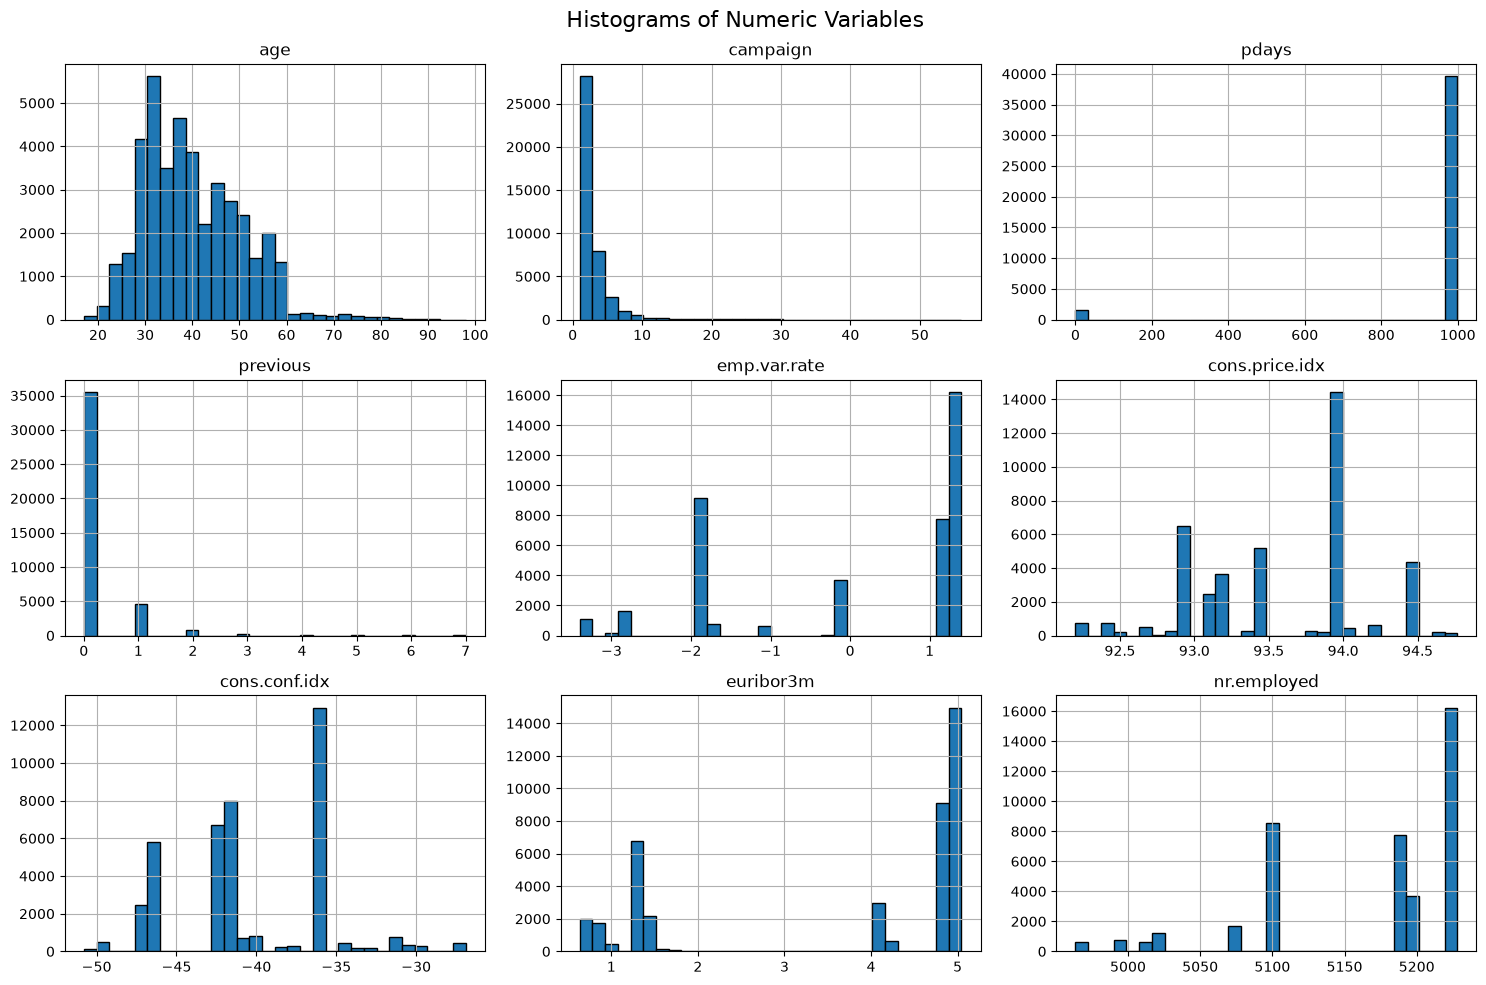

In [5]:
# histogram for each numeric column (3 rows x 3 columns of charts)
df[num_cols].hist(bins=30, figsize=(15, 10), edgecolor="black")
plt.suptitle("Histograms of Numeric Variables", fontsize=16)
plt.tight_layout()
plt.show()

### 2.1.3 Outliers (Box Plots)
Box plots show the middle 50% of values (the box) and mark unusual values as dots.

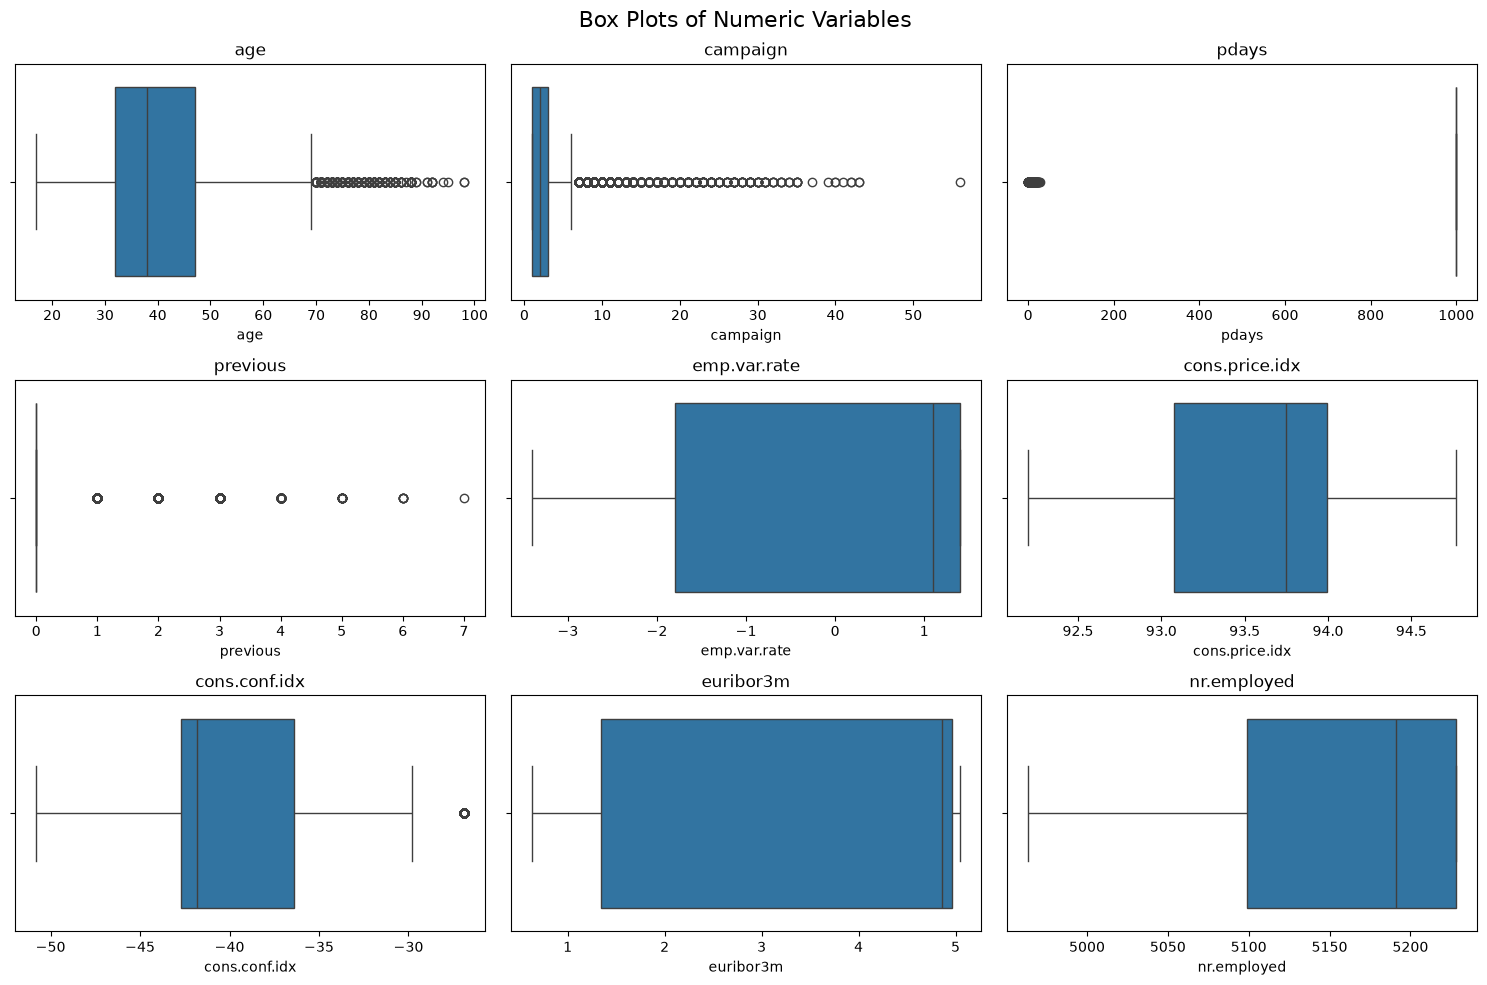

In [6]:
# one box plot per numeric column (separate charts because the scales are very different)
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
plt.suptitle("Box Plots of Numeric Variables", fontsize=16)
plt.tight_layout()
plt.show()

**Interpretation:**
- `age` has upper outliers (about 70–98). These are realistic older clients, not data errors.
- `campaign` has many outliers (from about 7 up to 56 calls). This is the most important outlier problem and suggests capping or a log transformation.
- In `pdays` the box collapses at 999, so the real day values (0–27) are wrongly shown as outliers. This confirms that 999 is a code and must be recoded.
- In `previous` every value above 0 is flagged, simply because most clients have 0. These are valid values, not errors.
- `cons.conf.idx` has one outlier (about −27), which is a real monthly economic value.
- Not every box-plot outlier is an error; each one must be judged in context before deciding how to treat it.

### 2.1.4 Correlation Between Numeric Variables
The heatmap shows how strongly each pair of numeric variables moves together (from -1 to +1).

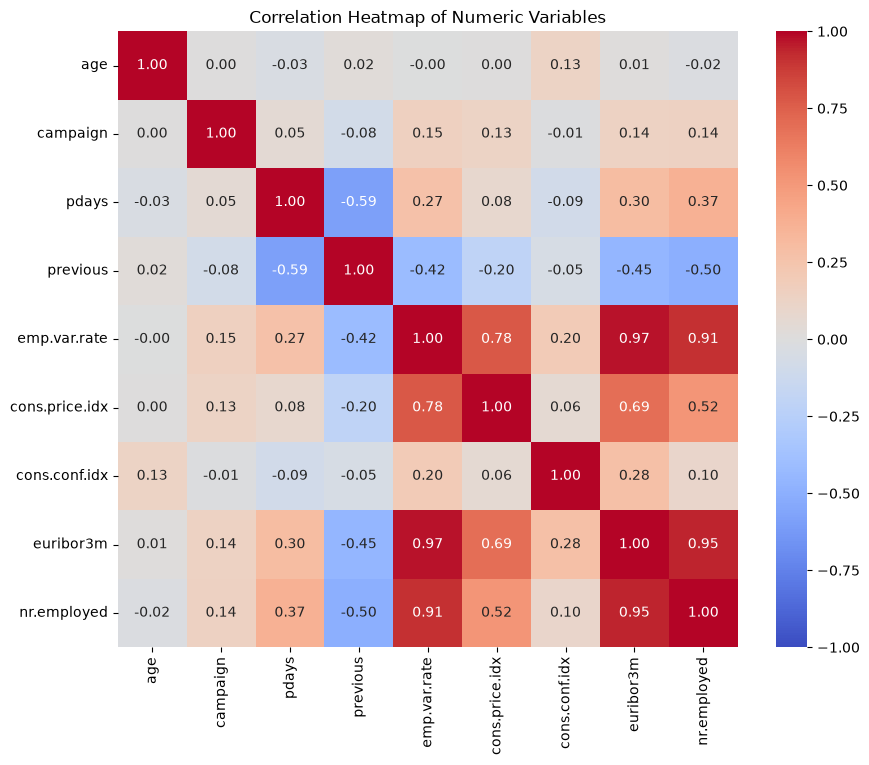

In [7]:
# correlation between every pair of numeric columns
corr = df[num_cols].corr()

# draw it as a coloured grid with the numbers shown
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Numeric Variables")
plt.show()

### 2.1.5 Scatter Plot
Checking visually how the two most correlated economic variables move together.

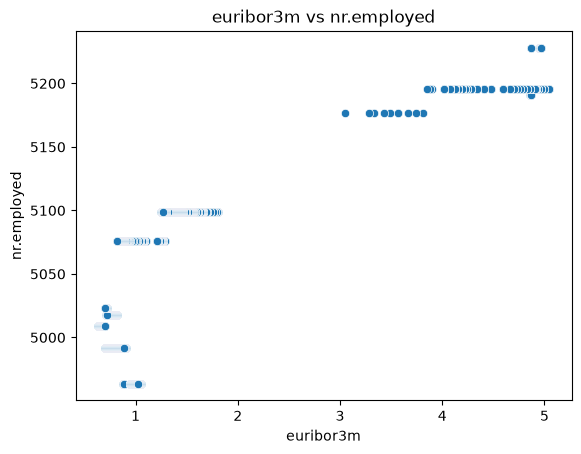

In [8]:
# scatter plot of the two most correlated economic variables
sns.scatterplot(x="euribor3m", y="nr.employed", data=df)
plt.title("euribor3m vs nr.employed")
plt.show()

**Interpretation:** The scatter plot confirms the strong positive relationship between `euribor3m` and `nr.employed` (r = 0.95): higher interest rates appear together with higher employment. The points form horizontal bands because `nr.employed` takes only 11 distinct values, recorded per time period rather than per client, so many points overlap. This visual redundancy supports checking these variables with VIF and combining them with PCA later.

## 2.2 Categorical Variables

In [9]:
# Separating into only string (obj) features

strFeatures = df.drop(columns="y").select_dtypes(include="object").columns.tolist() # selects all features to a list (excluding y)
df[strFeatures].head()

C:\Users\Leaki\AppData\Local\Temp\ipykernel_17724\735490841.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  strFeatures = df.drop(columns="y").select_dtypes(include="object").columns.tolist() # selects all features to a list (excluding y)


,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome
0,housemaid,married,basic.4y,no,no,no,telephone,may,mon,nonexistent
1,services,married,high.school,unknown,no,no,telephone,may,mon,nonexistent
2,services,married,high.school,no,yes,no,telephone,may,mon,nonexistent
3,admin.,married,basic.6y,no,no,no,telephone,may,mon,nonexistent
4,services,married,high.school,no,no,yes,telephone,may,mon,nonexistent


**Interperatation:** Job, contact, month, day_of_week, marital and poutcome are all nominal features as, for example a persons job type has no inherent hierarchy; default, housing and loan are also nominal but are binary features (yes or no).

Education is a ordinal feature as education level does have a hierarchy.

### 2.2.1 Summary Statistics

In [10]:
df.select_dtypes(include="object").describe()


C:\Users\Leaki\AppData\Local\Temp\ipykernel_17724\1519188749.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include="object").describe()


,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,y
count,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188
unique,12,4,8,3,3,3,2,10,5,3,2
top,admin.,married,university.degree,no,yes,no,cellular,may,thu,nonexistent,no
freq,10422,24928,12168,32588,21576,33950,26144,13769,8623,35563,36548


**Interperatation:** All features have 41,188 values so there are no empty values however there still could be other versions of missing values such as "unknown", "N/A" etc which is confirmed since default, housing and loan (which are all yes or no values) have 3 unique values. There are 12 different jobs listed in this dataset.
The modes are also displayed here in the "top" row, the mode of poutcome  is "nonexistent" which may seem like a missing value but is not.

In [11]:
df.select_dtypes(include="object").nunique()

C:\Users\Leaki\AppData\Local\Temp\ipykernel_17724\251659734.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.select_dtypes(include="object").nunique()


job            12
marital         4
education       8
default         3
housing         3
loan            3
contact         2
month          10
day_of_week     5
poutcome        3
y               2
dtype: int64

### 2.2.2 Count Histrograms
Histograms for the count and percentage of each categorical feature



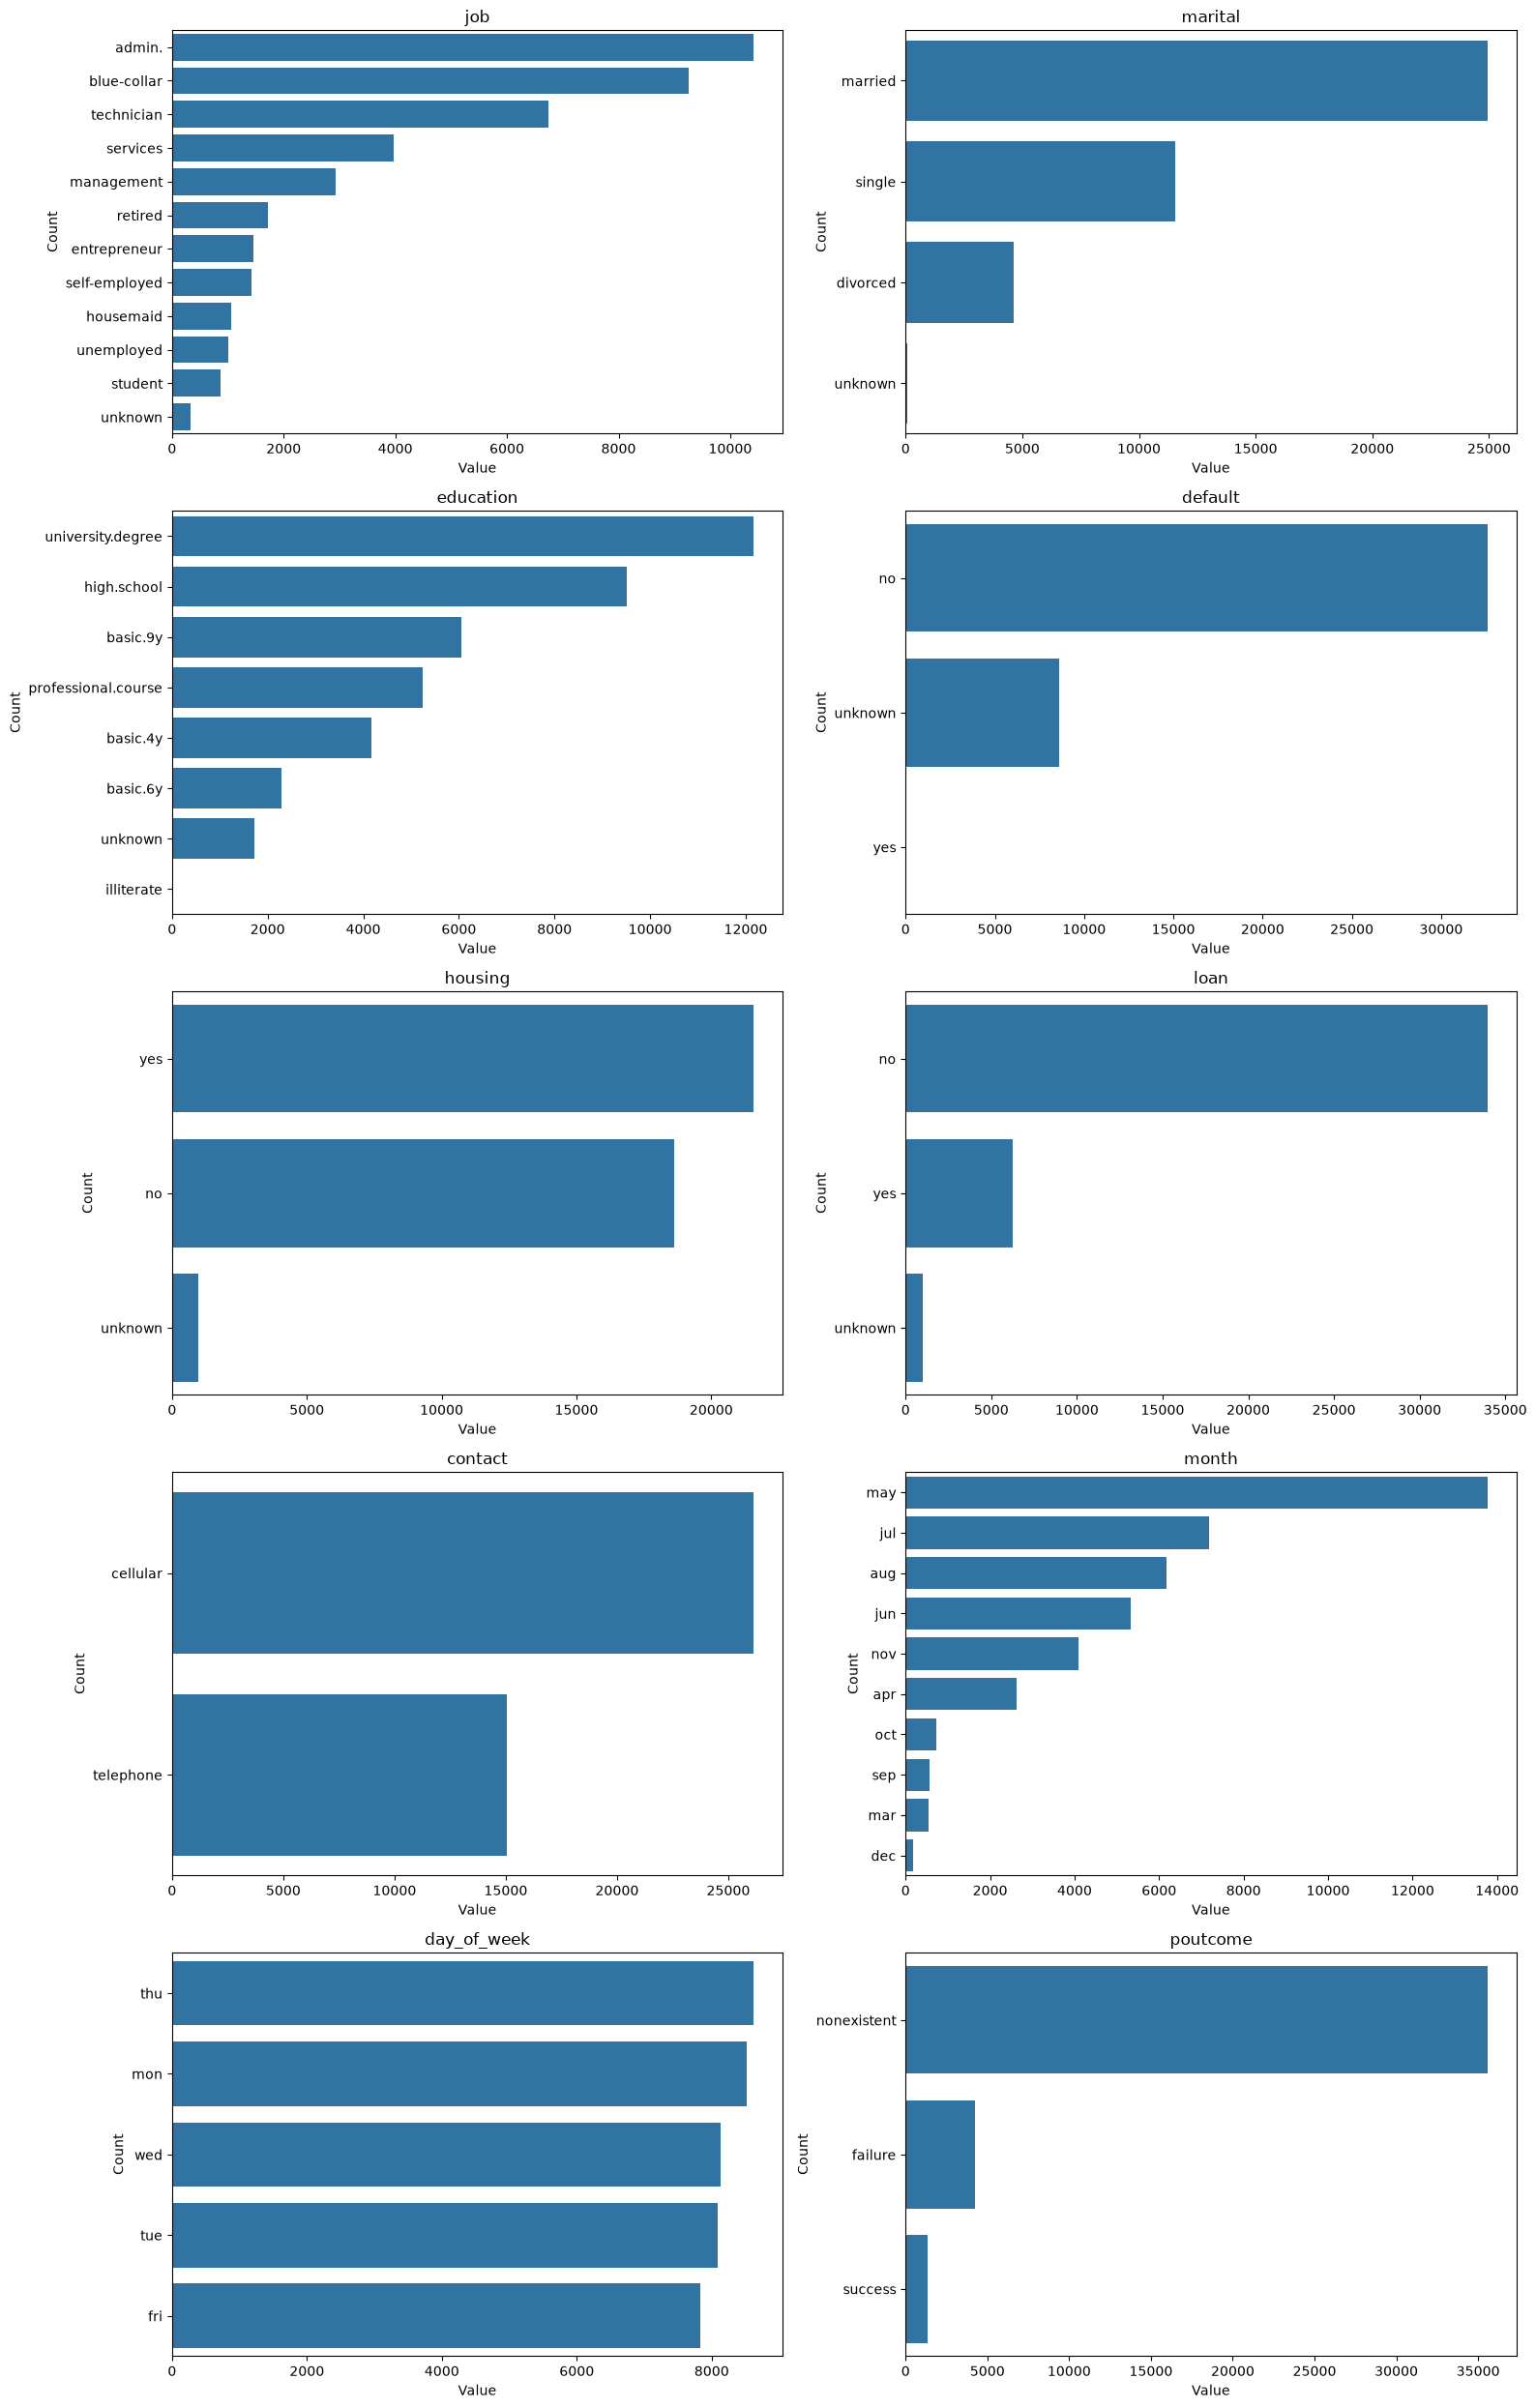

In [12]:
fig, axes = plt.subplots(5, 2, figsize=(16, 25))
axes = axes.flatten()

for i, col in enumerate(df[strFeatures]):
  # get percentage instead of count
  counts = (df[col].value_counts()).reset_index()
  counts.columns = ['Value', 'Count']

  sns.barplot(data=counts, x="Count", y="Value", ax=axes[i])
  #change figsize with rc instead of plt
  axes[i].set_title(col)
  axes[i].set_xlabel('Value')
  axes[i].set_ylabel('Count')

plt.tight_layout()
plt.show()


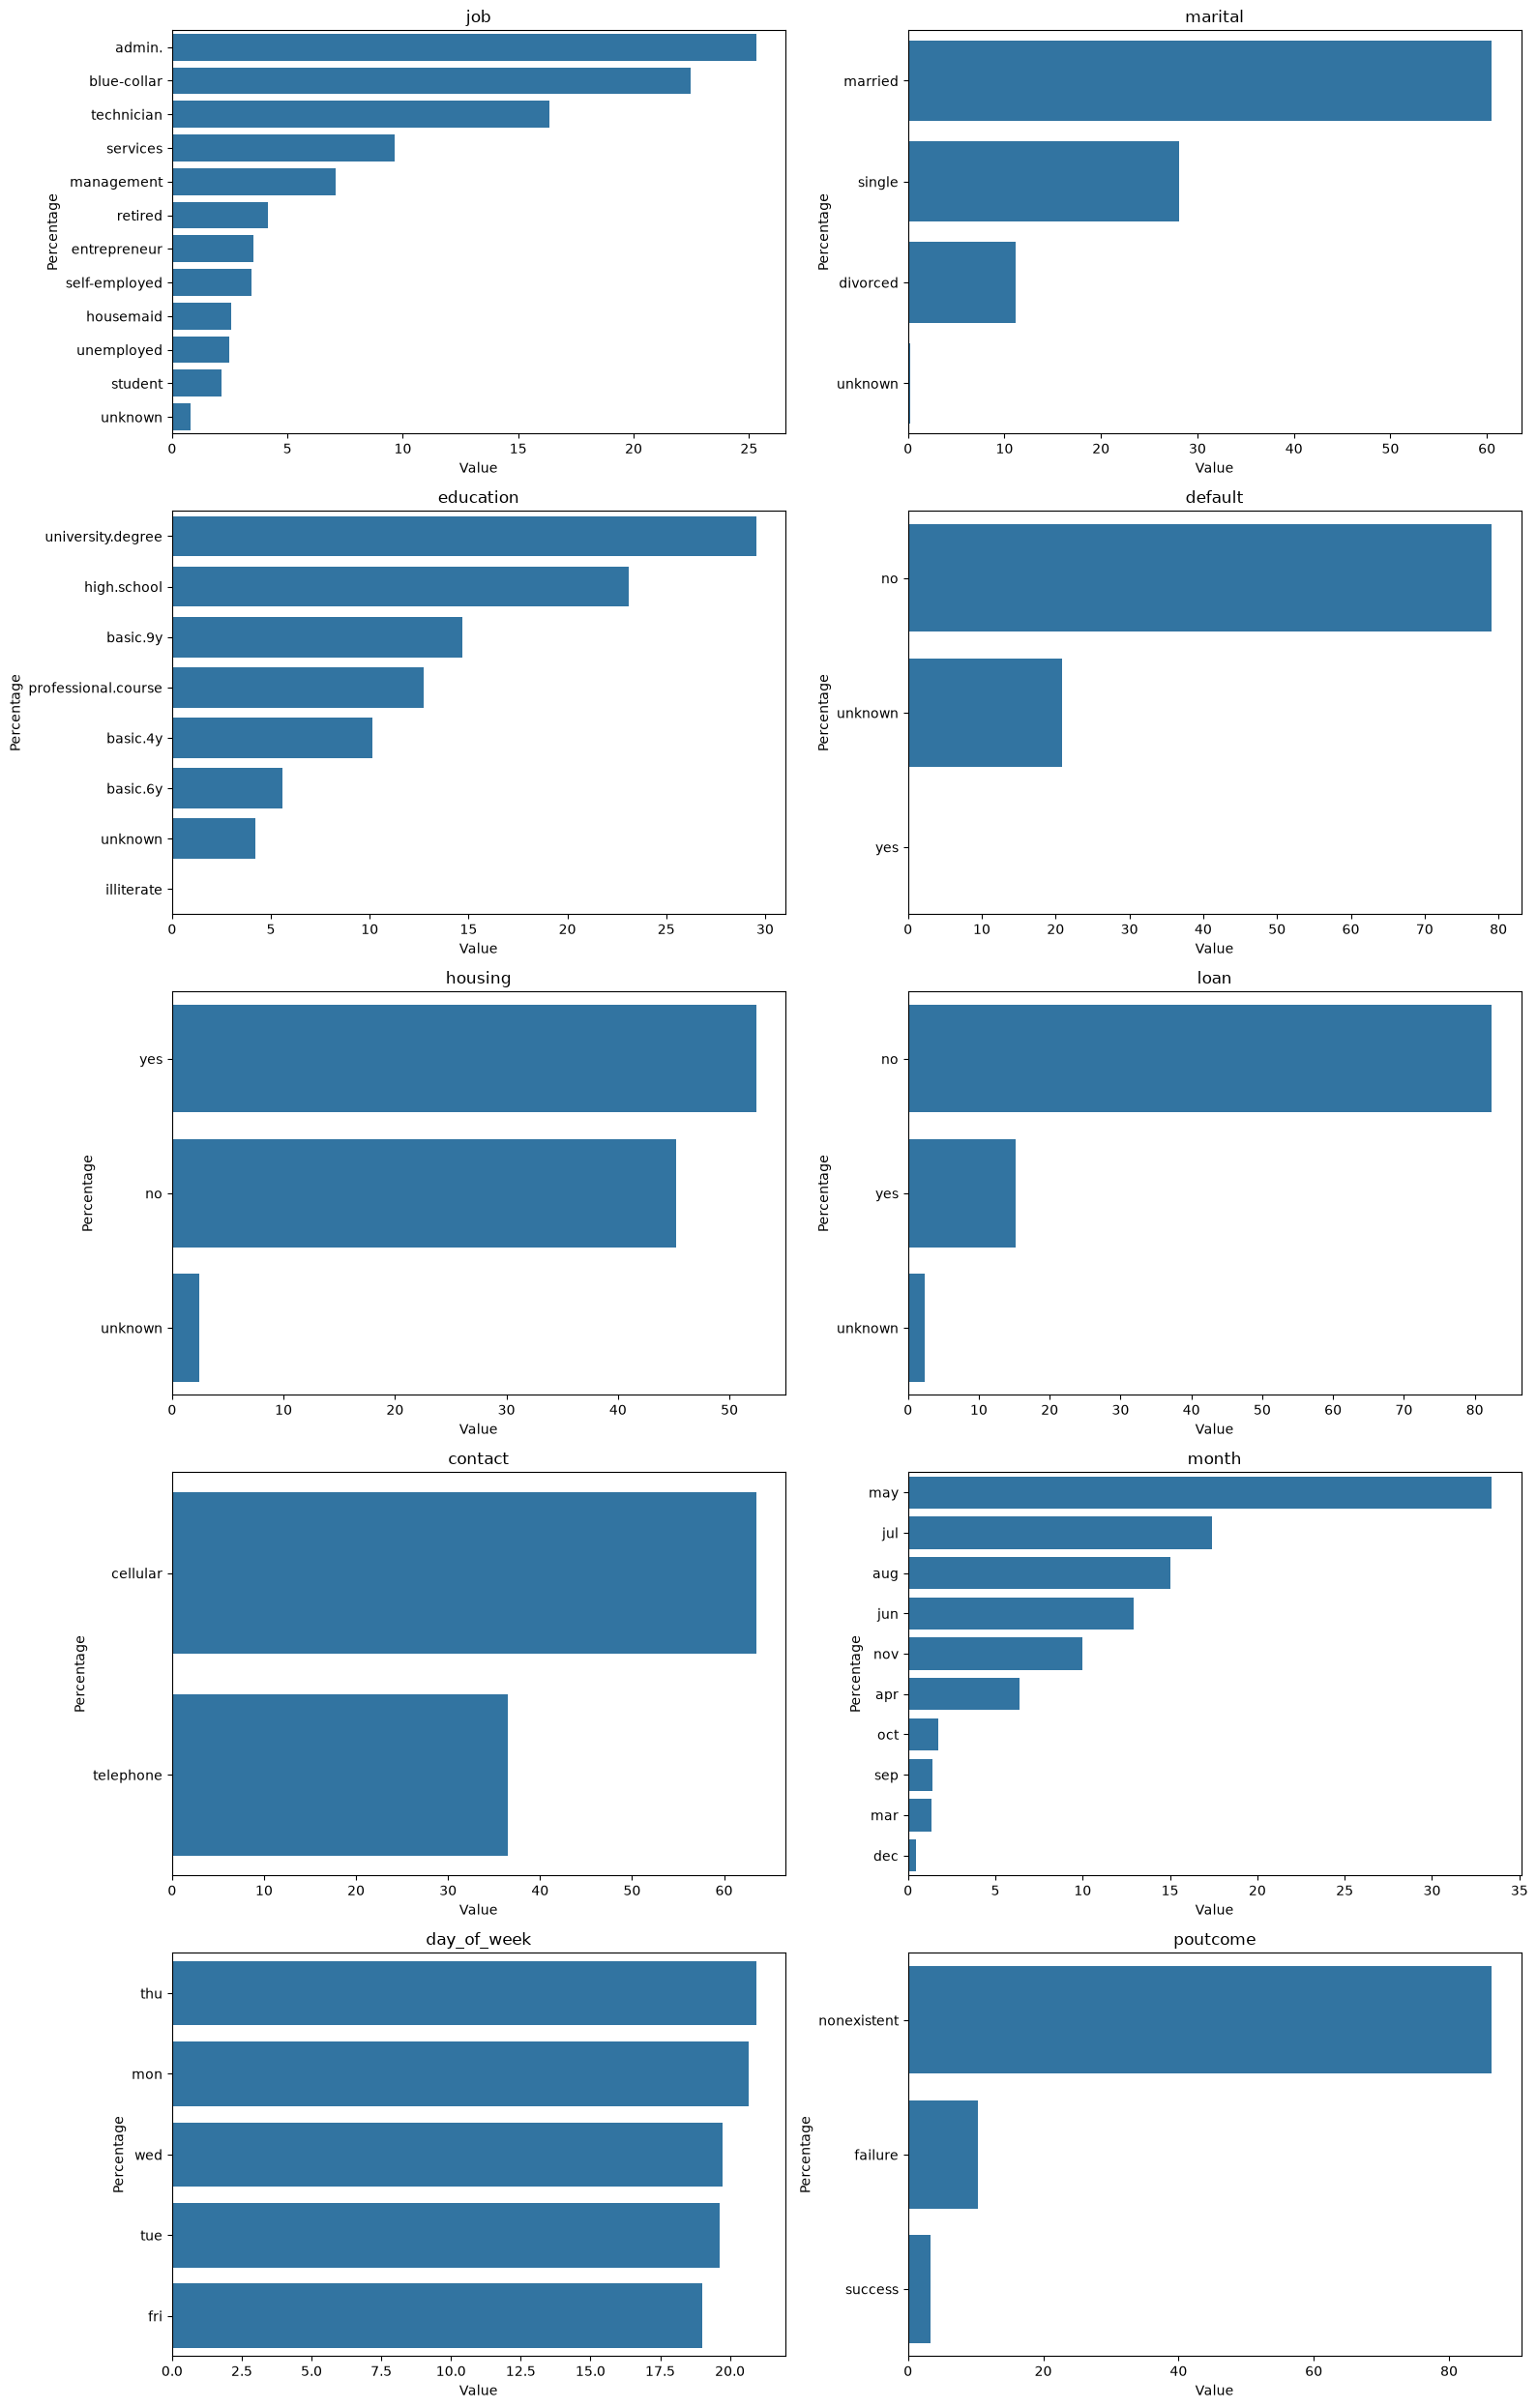

In [13]:
fig, axes = plt.subplots(5, 2, figsize=(16, 25))
axes = axes.flatten()

for i, col in enumerate(df[strFeatures]):
  # get percentage instead of count
  counts = (df[col].value_counts(normalize=True)* 100).reset_index()
  counts.columns = ['Value', 'Percentage']

  sns.barplot(data=counts, x="Percentage", y="Value", ax=axes[i])
  #change figsize with rc instead of plt
  axes[i].set_title(col)
  axes[i].set_xlabel('Value')
  axes[i].set_ylabel('Percentage')

plt.tight_layout()
plt.show()

**Interperatation:** Most of these features are fairly balanced however most values for poutcome are heavily imbalanced with it mostly being "nonexistent", some features have a few "unknown" values though this will be looked into further with the missingness summary, loan is also an imbalanced feature.

### 2.2.3 Target Balance

y
no     0.887346
yes    0.112654
Name: proportion, dtype: float64


<Axes: xlabel='y', ylabel='count'>

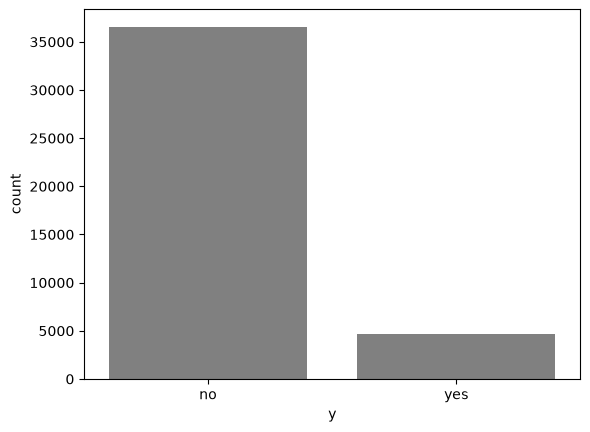

In [14]:
targetPercentage = df["y"].value_counts(normalize=True)
print(targetPercentage)
sns.countplot(x="y", color="gray", data=df)

**Interpretatioh:** Targets are imbalanced with around 88.7% no and 11.3% yes so a vast majority of rows are no, target is also proven to have no missing values.

### 2.2.4 Target Rate Per Feature

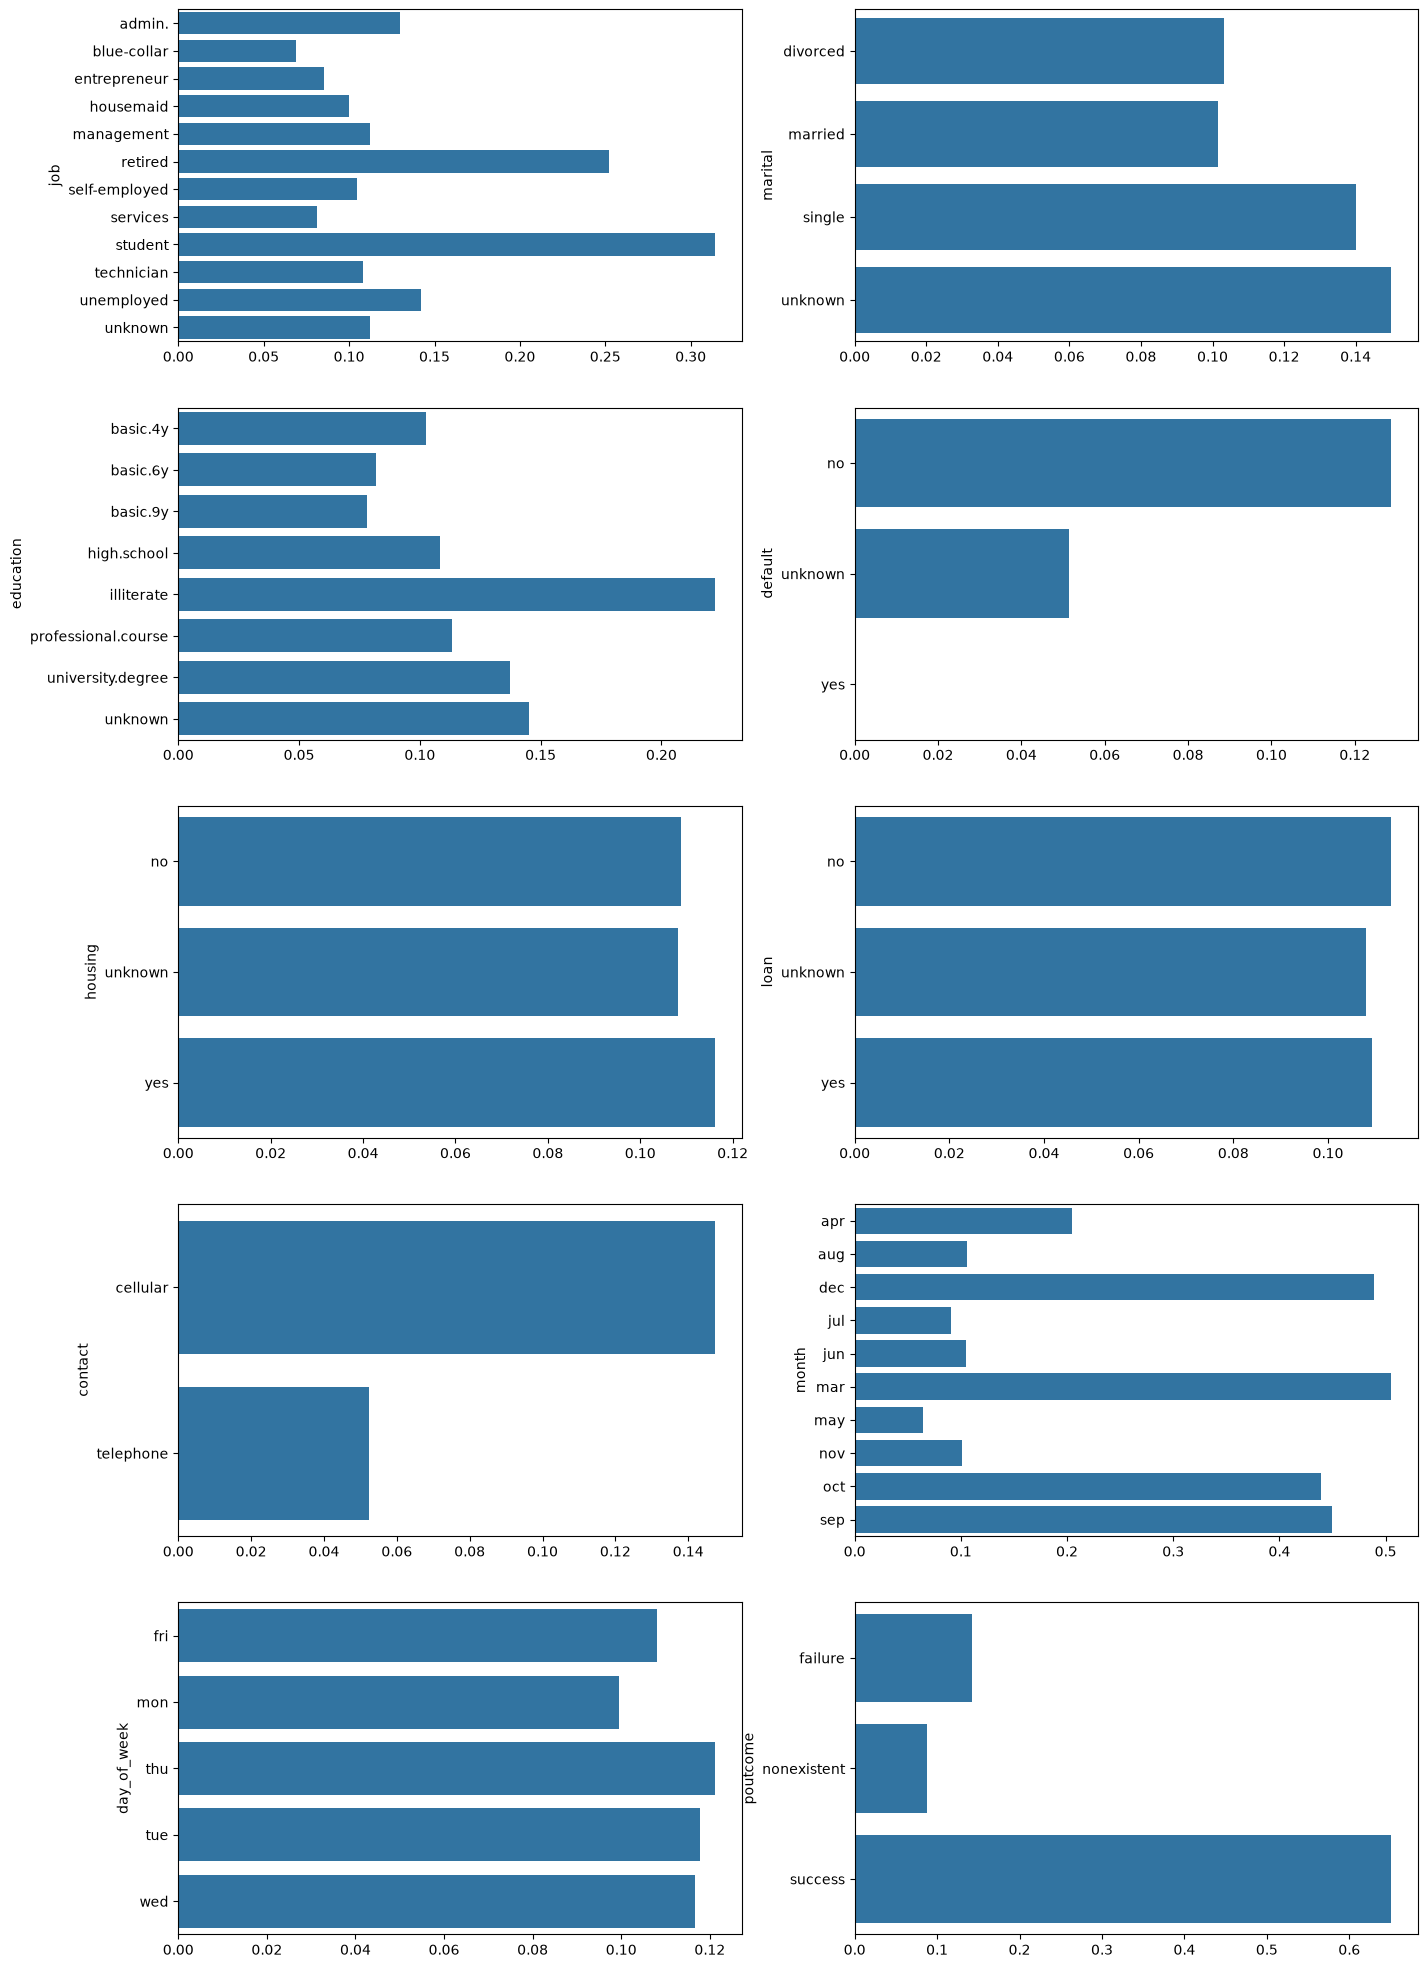

In [15]:
bankData = df.copy()
# Finding yes values
bankData["yes"] = (df['y']=='yes')
fig, axes = plt.subplots(5, 2, figsize=(16, 5 * 5))
axes = axes.flatten()


for i, col in enumerate(strFeatures):
  # Yes grouped by feature
  rate = bankData.groupby(col)['yes'].mean()
  sns.barplot(x=rate.values, y=rate.index, ax=axes[i])
for i in range(len(strFeatures), len(axes)):
    fig.delaxes(axes[i])

plt.show()

**Interpretatioh:** Student has the highest yes rate for jobs with over 30% of, highest yes rate for marital is an missing value ("unknown"), illiterate has the highest yes rate for education with over 20%, a default of no has the highest yes rate, so more likely to be yes if the customer does not have overdue loan, if the previous marketing campaign is a success for this person the yes rate is higher
Of course the yes rate for the actualy target column yes is 100%, this is just a control plot to see that the values are correct.
Overall the yes-rates for all features except day_of_week, housing, loan and marital are all quite spread out.

## 3. Data Quality and Cleaning
### 3.1 Duplicate Rows
Checking whether any rows are exact copies of another row.

In [16]:
# count rows that are exact copies of an earlier row
print("Duplicate rows:", df.duplicated().sum())

# show the duplicated rows next to their copies
df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(10)

Duplicate rows: 12


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
28476,24,services,single,high.school,no,yes,no,cellular,apr,tue,...,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
28477,24,services,single,high.school,no,yes,no,cellular,apr,tue,...,1,999,0,nonexistent,-1.8,93.075,-47.1,1.423,5099.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
32505,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,...,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
32516,35,admin.,married,university.degree,no,yes,no,cellular,may,fri,...,4,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no


In [17]:
# remove exact duplicate rows (keep the first copy)
df = df.drop_duplicates().reset_index(drop=True)
print("Rows after removing duplicates:", df.shape[0])

Rows after removing duplicates: 41176


**Interpretation:** 12 rows (0.03%) were exact duplicates across all 21 columns, including call duration in seconds, so they are very likely repeated records rather than different clients. They were removed, leaving 41,176 rows.

### 3.2 Data Types
Checking that each numeric variable is stored as a number.

In [18]:
# data type and number of different values for each numeric column
pd.DataFrame({"dtype": df[num_cols].dtypes,
              "unique_values": df[num_cols].nunique()})

,dtype,unique_values
age,int64,78
campaign,int64,42
pdays,int64,27
previous,int64,8
emp.var.rate,float64,10
cons.price.idx,float64,26
cons.conf.idx,float64,26
euribor3m,float64,316
nr.employed,float64,11


In [19]:
# data type and number of different values for each catgorical column
pd.DataFrame({"dtype": df[strFeatures].dtypes,
              "unique_values": df[strFeatures].nunique()})

,dtype,unique_values
job,str,12
marital,str,4
education,str,8
default,str,3
housing,str,3
loan,str,3
contact,str,2
month,str,10
day_of_week,str,5
poutcome,str,3


**Interpretation:** All numeric variables are stored with correct types: counts and ages as integers (`int64`) and economic indicators as decimals (`float64`), so no type conversion is needed. The economic indicators have very few distinct values (10–26, except `euribor3m` with 316) because they are recorded per time period rather than per client. `pdays` has 27 distinct values, one of which is the 999 code.

### 3.3 Outliers (IQR Method)
Counting values outside 1.5 × IQR to decide whether they are errors or valid extreme values.

In [20]:
# IQR rule: values below Q1 - 1.5*IQR or above Q3 + 1.5*IQR are outliers
q1 = df[num_cols].quantile(0.25)
q3 = df[num_cols].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

# count outliers per column
n_out = ((df[num_cols] < lower) | (df[num_cols] > upper)).sum()
pd.DataFrame({"lower_limit": lower, "upper_limit": upper,
              "outliers": n_out, "percent": (n_out / len(df) * 100).round(2)})

,lower_limit,upper_limit,outliers,percent
age,9.5000,69.5000,468,1.14
campaign,-2.0000,6.0000,2406,5.84
pdays,999.0000,999.0000,1515,3.68
previous,0.0000,0.0000,5625,13.66
emp.var.rate,-6.6000,6.2000,0,0.00
cons.price.idx,91.6965,95.3725,0,0.00
cons.conf.idx,-52.1500,-26.9500,446,1.08
euribor3m,-4.0815,10.3865,0,0.00
nr.employed,4905.6000,5421.6000,0,0.00


### 3.4 Recoding `pdays` (999 code)
`pdays = 999` means the client was never contacted before. It is a code, not a real number of days, so it is replaced with a yes/no indicator.

In [21]:
# new yes/no column: 1 = contacted in a previous campaign, 0 = never (999)
df["prev_contacted"] = (df["pdays"] != 999).astype(int)
print(df["prev_contacted"].value_counts())

# remove the original pdays column and update the numeric list
df = df.drop(columns="pdays")
num_cols.remove("pdays")
print("Numeric columns now:", num_cols)

prev_contacted
0    39661
1     1515
Name: count, dtype: int64
Numeric columns now: ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


**Interpretation:** 999 was replaced by a binary indicator `prev_contacted` (1 = contacted in a previous campaign, 0 = never). Only 1,515 clients (3.7%) had been contacted before, while 39,661 had the 999 code. The original `pdays` column was removed, as its exact day values applied to very few clients and the 999 code would mislead later steps such as scaling and PCA. The number of previous contacts is still kept in `previous`. This is a fixed rule (not learned from the data), so it does not cause data leakage.

In [22]:
# previous says "contacted before" but pdays said 999 ("never")
print("previous > 0 but prev_contacted = 0:",
      ((df["previous"] > 0) & (df["prev_contacted"] == 0)).sum())

# does poutcome agree with prev_contacted?
pd.crosstab(df["poutcome"], df["prev_contacted"])

previous > 0 but prev_contacted = 0: 4110


prev_contacted,0,1
poutcome,,
failure,4110,142
nonexistent,35551,0
success,0,1373


**Interpretation:** 4,110 clients have previous > 0 but pdays = 999. All of them have poutcome = "failure", so pdays was mostly not recorded after a failed campaign; poutcome is the more reliable column. prev_contacted = 1 for all 1,373 successes but only 142 failures, so it mostly repeats poutcome = "success" (nearly redundant). Kept for now; feature selection will decide.

### 3.5 Missingness Summary

In [23]:
unknownCount = (df.select_dtypes(include="object") == 'unknown').sum()
unknownPercent = (df[strFeatures].apply(lambda col: col.eq("unknown").mean()*100))


print(unknownCount)
print(unknownPercent)

job             330
marital          80
education      1730
default        8596
housing         990
loan            990
contact           0
month             0
day_of_week       0
poutcome          0
y                 0
dtype: int64
job             0.801438
marital         0.194288
education       4.201477
default        20.876239
housing         2.404313
loan            2.404313
contact         0.000000
month           0.000000
day_of_week     0.000000
poutcome        0.000000
dtype: float64


C:\Users\Leaki\AppData\Local\Temp\ipykernel_17724\458986832.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  unknownCount = (df.select_dtypes(include="object") == 'unknown').sum()


C:\Users\Leaki\AppData\Local\Temp\ipykernel_17724\2653213515.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  unknownCount = (df.select_dtypes(include="object") == 'unknown').sum()
C:\Users\Leaki\AppData\Local\Temp\ipykernel_17724\2653213515.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/d

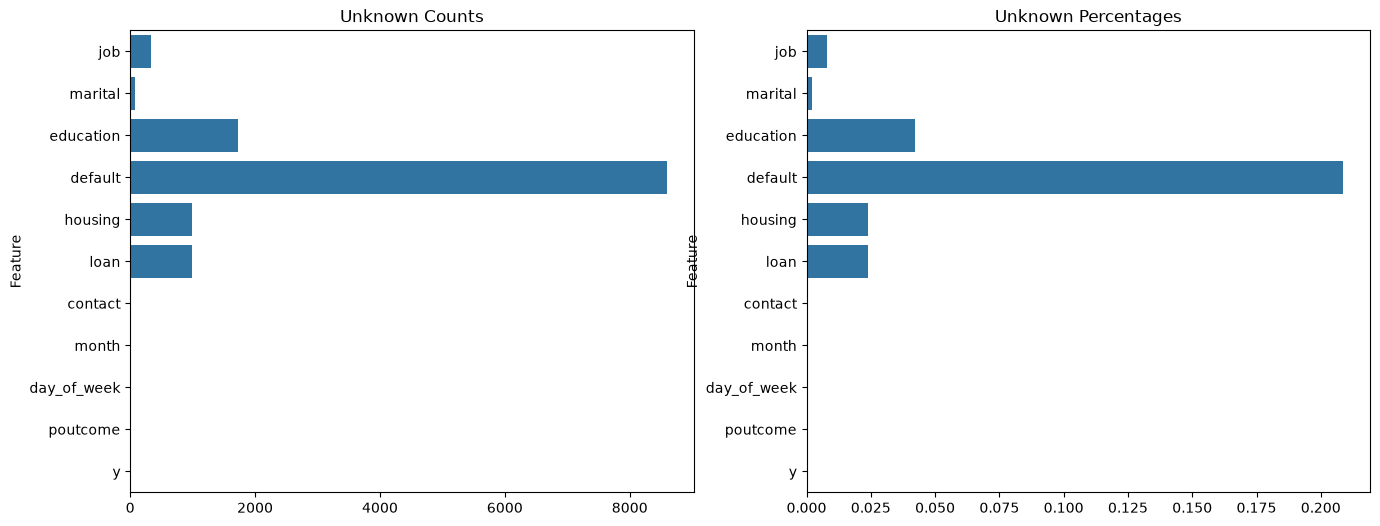

In [24]:
unknownCount = (df.select_dtypes(include="object") == 'unknown').sum()
unknownPercent = (df.select_dtypes(include="object") == 'unknown').mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

counts = sns.barplot(x=unknownCount.values, y=unknownCount.index , ax=axes[0])
counts.set_ylabel("Feature")
counts.set_title("Unknown Counts")


percents = sns.barplot(x=unknownPercent.values, y=unknownPercent.index, ax=axes[1])
percents.set_ylabel("Feature")
percents.set_title("Unknown Percentages")
plt.show()


**Interperatation:** default has the highest unknow rate, with over 20% of its rows being unknown and as seen previously it is heavily imbalanced too, this does not seem like an adequete feature for the final model. Contant, month, day_of_week, poutcome and the target feature have no uknowns.
No categorical feature has a fully missing/null values, as seen that every mean for isnull is 0.
Housing and loan have an equal number of 'unknown' rows so it may be suitable to keep unknown as its own value since it could be informative.

In [25]:
# Set which columns unknown values are being kept
keepCols = ['housing', 'loan']
replaceCols = df.columns.difference(keepCols)
# Replace unknown with NaN for pipeline (apart from housing and loan)
df[replaceCols] = df[replaceCols].replace('unknown', np.nan)

**Interperatation:** Keeping the unknown values in housing and loan (keepCols) since the unknowns are on the same rows which could be informative, replacing other unknowns with np.nan to prepare it for imputing in the pipeline.

## 4. Train/Test Split
The data is split into 80% training and 20% test before any further preparation, so the test data stays unseen.

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import numpy as np

df = df.loc[:,~df.columns.duplicated()].copy()
# for encoding target
le = LabelEncoder()

# X = the information about clients, y = the answer (yes/no)
X = df.drop(columns=["y", "duration"])
y = df["y"]

# cut into 80% train and 20% test, same yes/no mix in both
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

y_trainEncoded = le.fit_transform(y_train)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (32940, 19)  Test: (8236, 19)


**Interpretation:** The data was split into a training set (32,940 rows, 80%) and a test set (8,236 rows, 20%). The split is stratified on `y`, so both sets keep the same proportion of "yes" clients (about 11%). `random_state=42` makes the split reproducible. From now on, all preparation steps (scaling, transformations, PCA) are fitted on the training set only, and the test set is kept untouched.

## 5. Transformations
### 5.1 Log Transformation of `campaign`
`campaign` is strongly right-skewed (most clients 1–3 calls, maximum 56). A log(1 + x) transformation reduces the effect of extreme values while keeping their order.

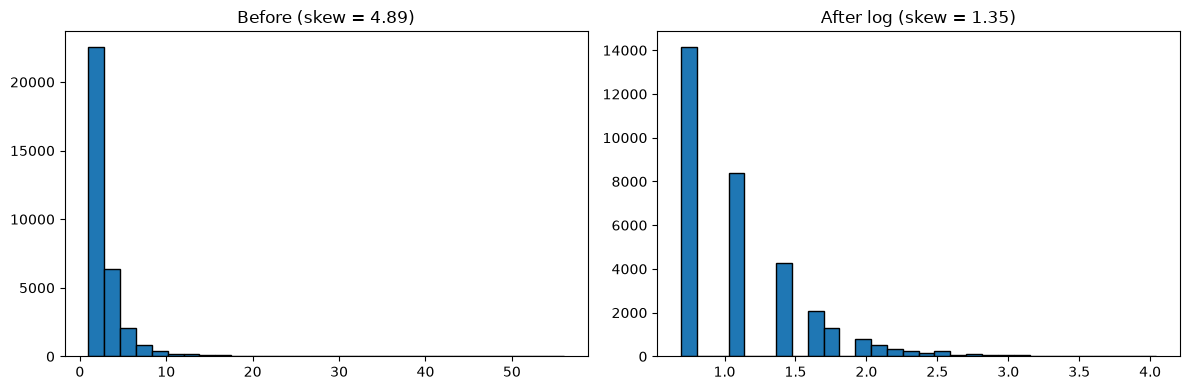

In [27]:
import numpy as np

# compare the shape before and after the log transform
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(X_train["campaign"], bins=30, edgecolor="black")
axes[0].set_title(f"Before (skew = {X_train['campaign'].skew():.2f})")

# log(1 + x) is a fixed formula, so it is applied the same way to both sets
X_train["campaign"] = np.log1p(X_train["campaign"])
X_test["campaign"] = np.log1p(X_test["campaign"])

axes[1].hist(X_train["campaign"], bins=30, edgecolor="black")
axes[1].set_title(f"After log (skew = {X_train['campaign'].skew():.2f})")
plt.tight_layout()
plt.show()

**Interpretation:** The log(1 + x) transformation reduced the skewness of `campaign` from 4.89 to 1.35, and the maximum value fell from 56 calls to about 4.0 on the log scale. The extreme values are kept (not removed) but have much less influence. Because the log is a fixed formula that does not learn from the data, it was applied to both the training and test sets without causing leakage.


### 5.2 Scaling Numeric Variables
The numeric variables are on very different scales (e.g. `nr.employed` ≈ 5,000 vs `euribor3m` ≈ 1–5). They are standardised to mean 0 and standard deviation 1. The scaler is fitted on the training set only and then applied to the test set, to avoid data leakage.

In [28]:
from sklearn.preprocessing import StandardScaler

# learn mean and std from the TRAINING set only, then apply to both sets
scaler = StandardScaler()
X_train_num = pd.DataFrame(scaler.fit_transform(X_train[num_cols]),
                           columns=num_cols, index=X_train.index)
X_test_num = pd.DataFrame(scaler.transform(X_test[num_cols]),
                          columns=num_cols, index=X_test.index)

# check: training means should be 0 and std 1
X_train_num.describe().T[["mean", "std"]].round(2)

,mean,std
age,-0.0,1.0
campaign,0.0,1.0
previous,0.0,1.0
emp.var.rate,-0.0,1.0
cons.price.idx,0.0,1.0
cons.conf.idx,0.0,1.0
euribor3m,-0.0,1.0
nr.employed,0.0,1.0


**Interpretation:** After standardisation, all eight numeric variables in the training set have a mean of 0 and a standard deviation of 1, so no variable dominates because of its original units (for example `nr.employed`, which was around 5,000). The scaler learned its parameters from the training set only, and the test set was transformed with those same parameters, so no test information leaked into the preparation. The binary `prev_contacted` indicator was not scaled.

### 5.3 Encoding and Imputing Categorical Features

In [29]:
from sklearn import preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder
from sklearn.compose import ColumnTransformer


ordinalCols = ['education']
binaryCols  = ['contact', 'housing', 'loan', 'default']
nominalCols = ['job', 'marital', 'poutcome', 'month', 'day_of_week']

# Order of values for ordinal encoding (aka 0,1,2,3 etc)
eduOrder = ['illiterate', 'basic.4y', 'basic.6y', 'basic.9y',
             'high.school', 'professional.course', 'university.degree']

#Creating Pipeline
encImpPreprocessor = ColumnTransformer([
    # ordinal: explicit order, unknown (NaN) imputed with mode
    ('ord', Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('enc', OrdinalEncoder(categories=[eduOrder]))
    ]), ordinalCols),

    # binary: impute then one-hot with drop='if_binary' to a single 0/1 column if feature has only 2 values
    ('bin', Pipeline([
        ('enc', OneHotEncoder(drop='if_binary', handle_unknown='ignore')),
        ('imp', SimpleImputer(strategy='most_frequent'))
    ]), binaryCols),

    # nominal: impute then one-hot
    ('nom', Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('enc', OneHotEncoder(handle_unknown='ignore'))
    ]), nominalCols)
])

# For feature selection
X_trainOriginal = X_train.copy()
X_trainEncoded = encImpPreprocessor.fit_transform(X_train)

# get feature names after encoding
strProcessedNames = encImpPreprocessor.get_feature_names_out()

print(strProcessedNames)
print(X_trainOriginal["prev_contacted"].shape)

['ord__education' 'bin__contact_telephone' 'bin__housing_no'
 'bin__housing_unknown' 'bin__housing_yes' 'bin__loan_no'
 'bin__loan_unknown' 'bin__loan_yes' 'bin__default_no' 'bin__default_yes'
 'bin__default_nan' 'nom__job_admin.' 'nom__job_blue-collar'
 'nom__job_entrepreneur' 'nom__job_housemaid' 'nom__job_management'
 'nom__job_retired' 'nom__job_self-employed' 'nom__job_services'
 'nom__job_student' 'nom__job_technician' 'nom__job_unemployed'
 'nom__marital_divorced' 'nom__marital_married' 'nom__marital_single'
 'nom__poutcome_failure' 'nom__poutcome_nonexistent'
 'nom__poutcome_success' 'nom__month_apr' 'nom__month_aug'
 'nom__month_dec' 'nom__month_jul' 'nom__month_jun' 'nom__month_mar'
 'nom__month_may' 'nom__month_nov' 'nom__month_oct' 'nom__month_sep'
 'nom__day_of_week_fri' 'nom__day_of_week_mon' 'nom__day_of_week_thu'
 'nom__day_of_week_tue' 'nom__day_of_week_wed']
(32940,)


## 6. Correlation, Multicollinearity and PCA
### 6.1 Correlation Matrix (Training Data)
The correlation matrix is recomputed on the training set only, to identify redundant numeric variables before VIF and PCA.

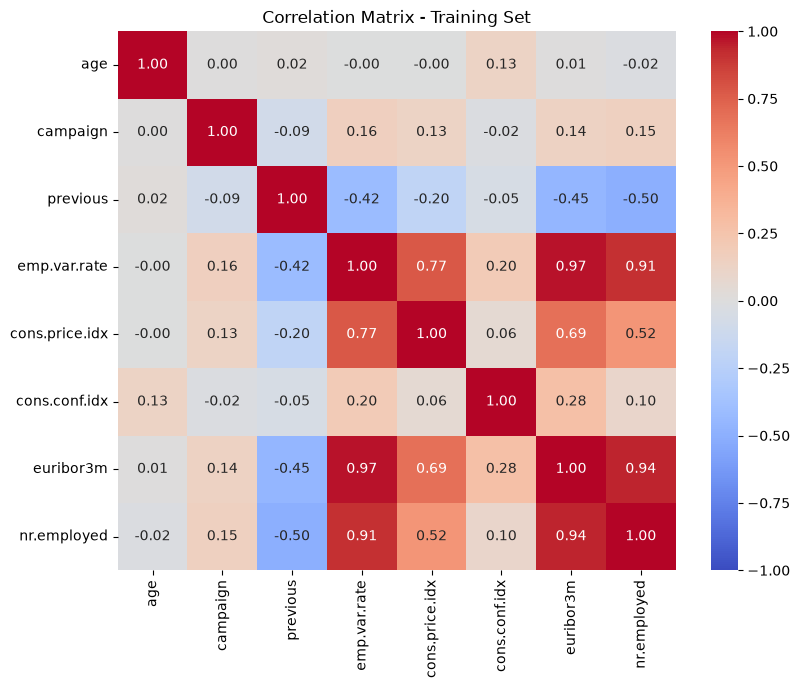

emp.var.rate  euribor3m      0.97
              nr.employed    0.91
euribor3m     nr.employed    0.94
dtype: float64


In [30]:
# correlation of the scaled numeric variables (training set only)
corr_train = X_train_num.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_train, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix - Training Set")
plt.show()

# list the strongly correlated pairs (|r| > 0.8)
pairs = corr_train.where(np.triu(np.ones(corr_train.shape, dtype=bool), k=1)).stack()
print(pairs[pairs.abs() > 0.8].round(2))

**Interpretation:** On the training set, three economic indicators remain very strongly correlated: `emp.var.rate`–`euribor3m` (0.97), `euribor3m`–`nr.employed` (0.94) and `emp.var.rate`–`nr.employed` (0.91). `cons.price.idx` is also strongly related to `emp.var.rate` (0.77). These values are almost identical to the EDA results on the full data, confirming that the training set is representative. `age`, `campaign` and `cons.conf.idx` show weak correlations with all other variables. The strong redundancy among the economic indicators will be measured with VIF next and addressed with PCA.

### 6.2 Multicollinearity (VIF)
The Variance Inflation Factor (VIF) measures how much each numeric variable can be predicted from all the others. VIF above 10 indicates severe multicollinearity.

In [31]:
# !pip install statsmodels

In [32]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools import add_constant

# VIF for each numeric variable (training set only)
X_vif = add_constant(X_train_num)
vif = pd.DataFrame({
    "variable": num_cols,
    "VIF": [variance_inflation_factor(X_vif.values, i + 1) for i in range(len(num_cols))]
}).sort_values("VIF", ascending=False).round(2)
vif

,variable,VIF
6,euribor3m,64.57
3,emp.var.rate,33.28
7,nr.employed,31.56
4,cons.price.idx,6.31
5,cons.conf.idx,2.61
2,previous,1.35
1,campaign,1.04
0,age,1.02


**Interpretation:** Three economic indicators show severe multicollinearity: `euribor3m` (VIF 64.6), `emp.var.rate` (33.3) and `nr.employed` (31.6), far above the threshold of 10. These variables largely describe the same economic conditions. `cons.price.idx` shows moderate overlap (6.3), while `cons.conf.idx`, `previous`, `campaign` and `age` have low VIF (below 3). Instead of deleting variables, PCA is applied next to combine the repeated information.

### 6.3 Principal Component Analysis (PCA)
PCA is fitted on the scaled numeric training data to combine correlated variables into uncorrelated components. The explained variance shows how much information each component keeps.

  component  explained_%  cumulative_%
0       PC1         46.7          46.7
1       PC2         14.2          60.9
2       PC3         12.2          73.1
3       PC4         10.6          83.7
4       PC5         10.6          94.3
5       PC6          5.3          99.6
6       PC7          0.3          99.9
7       PC8          0.1         100.0


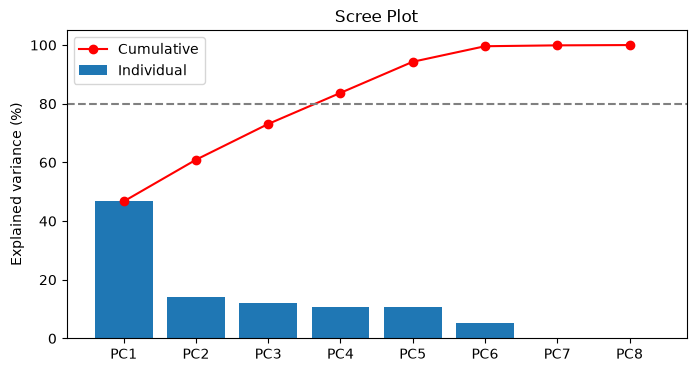

In [33]:
from sklearn.decomposition import PCA

# fit PCA on the scaled numeric training data
pca = PCA()
pca.fit(X_train_num)

# how much information (variance) each component keeps
expl = pca.explained_variance_ratio_
pca_table = pd.DataFrame({"component": [f"PC{i+1}" for i in range(len(expl))],
                          "explained_%": (expl * 100).round(1),
                          "cumulative_%": (expl.cumsum() * 100).round(1)})
print(pca_table)

# scree plot: bars = each component, line = running total
plt.figure(figsize=(8, 4))
plt.bar(pca_table["component"], pca_table["explained_%"], label="Individual")
plt.plot(pca_table["component"], pca_table["cumulative_%"], marker="o", color="red", label="Cumulative")
plt.axhline(80, linestyle="--", color="grey")
plt.ylabel("Explained variance (%)")
plt.title("Scree Plot")
plt.legend()
plt.show()

**Interpretation:** PC1 alone explains 46.7% of the variance, mainly reflecting the strongly correlated economic indicators. The first four components together explain 83.7%, passing the common 80% threshold, and five components explain 94.3%. PC7 and PC8 explain only 0.4% combined, which confirms the multicollinearity found with VIF: the eight numeric variables contain about six dimensions of genuinely different information.

### 6.4 Choosing the Number of Components
Four components are kept: this is the smallest number that explains more than 80% of the variance (83.7%), reducing the numeric variables from 8 to 4.

In [34]:
# keep 4 components, learned from the TRAINING set only
pca4 = PCA(n_components=4)
X_train_pca = pd.DataFrame(pca4.fit_transform(X_train_num),
                           columns=["PC1", "PC2", "PC3", "PC4"], index=X_train.index)
X_test_pca = pd.DataFrame(pca4.transform(X_test_num),
                          columns=["PC1", "PC2", "PC3", "PC4"], index=X_test.index)

print("Train:", X_train_pca.shape, " Test:", X_test_pca.shape)
print("Variance kept:", round(pca4.explained_variance_ratio_.sum() * 100, 1), "%")

Train: (32940, 4)  Test: (8236, 4)
Variance kept: 83.7 %


**Interpretation:** The eight scaled numeric variables were reduced to four principal components, which keep 83.7% of the variance. PCA was fitted on the training set only and the same transformation was applied to the test set, so no test information was used. This halves the number of numeric features while removing the multicollinearity, because principal components are uncorrelated with each other.

### 6.5 Interpreting the Components (Loadings)
Loadings show how strongly each original variable contributes to each component.

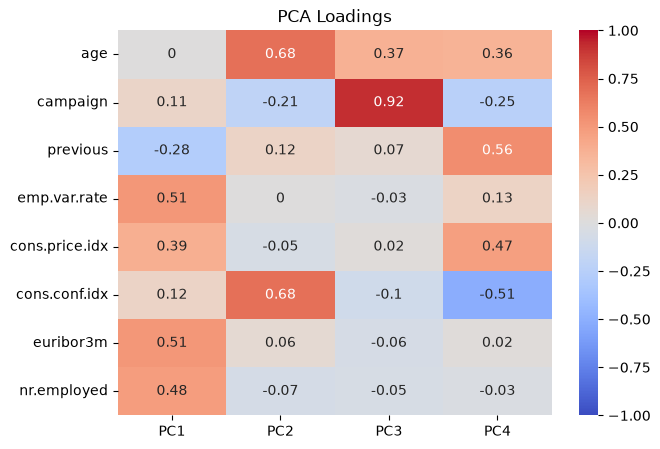

In [35]:
# loadings: contribution of each original variable to each component
loadings = pd.DataFrame(pca4.components_.T, index=num_cols,
                        columns=["PC1", "PC2", "PC3", "PC4"]).round(2)

plt.figure(figsize=(7, 5))
sns.heatmap(loadings, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("PCA Loadings")
plt.show()

**Interpretation:**
- **PC1 (46.7%) – economic conditions:** high, similar loadings on `emp.var.rate` (0.51), `euribor3m` (0.51) and `nr.employed` (0.48), plus `cons.price.idx` (0.39). PC1 combines the redundant economic indicators into a single component.
- **PC2 (14.2%) – age and consumer confidence:** driven by `age` (0.68) and `cons.conf.idx` (0.68).
- **PC3 (12.2%) – campaign intensity:** almost entirely `campaign` (0.92), i.e. the number of calls in the current campaign.
- **PC4 (10.6%) – previous contact and price/confidence:** `previous` (0.56), `cons.price.idx` (0.47) and `cons.conf.idx` (−0.51).

PC1 and PC3 have a clear meaning, while PC2 and PC4 mix variables that are not naturally related, which makes them harder to interpret. This is a known limitation of PCA and will be weighed against feature selection, which keeps the original, interpretable variables.

## 7. Feature Selection

### 7.1 Near-constant Features

In [36]:
# Percents for each feature
nearConstant = pd.Series({
    col: X_train[col].value_counts(normalize=True, dropna=False).iloc[0]
    for col in X_train.columns
}).sort_values(ascending=False)

print(nearConstant)                       # every column, most dominated first
print(nearConstant[nearConstant > 0.75])  # only displayed > 75% dominated

prev_contacted    0.963358
previous          0.863115
poutcome          0.863115
loan              0.824438
default           0.791773
contact           0.635671
marital           0.604584
housing           0.524529
campaign          0.429812
nr.employed       0.394566
emp.var.rate      0.394566
month             0.334517
education         0.295112
job               0.251032
day_of_week       0.207620
cons.conf.idx     0.187492
cons.price.idx    0.187492
euribor3m         0.068822
age               0.048027
dtype: float64
prev_contacted    0.963358
previous          0.863115
poutcome          0.863115
loan              0.824438
default           0.791773
dtype: float64


**Interpretation:** As seen in the previous graphs default is near-constant with no being 79% of the values, this would be even higher after the test/train split so it would not give the model much information, this could also cause overfitting. prev_contacted, previous and poutcome are also all near-constant which is most likely because they are all hold similar information.

In [37]:
from sklearn.preprocessing import StandardScaler
stScalar = StandardScaler()

if hasattr(X_trainEncoded, "toarray"):
    X_trainEncoded = X_trainEncoded.toarray()
numFeatures = X_train.select_dtypes(include=np.number).columns
X_trainNum = stScalar.fit_transform(X_train[numFeatures])
X_trainAll = np.hstack([X_trainEncoded, X_trainNum])

**Interpretation:** Scaling and combining categorical and numerical features for feature selection.

### 7.2 Chi Squared

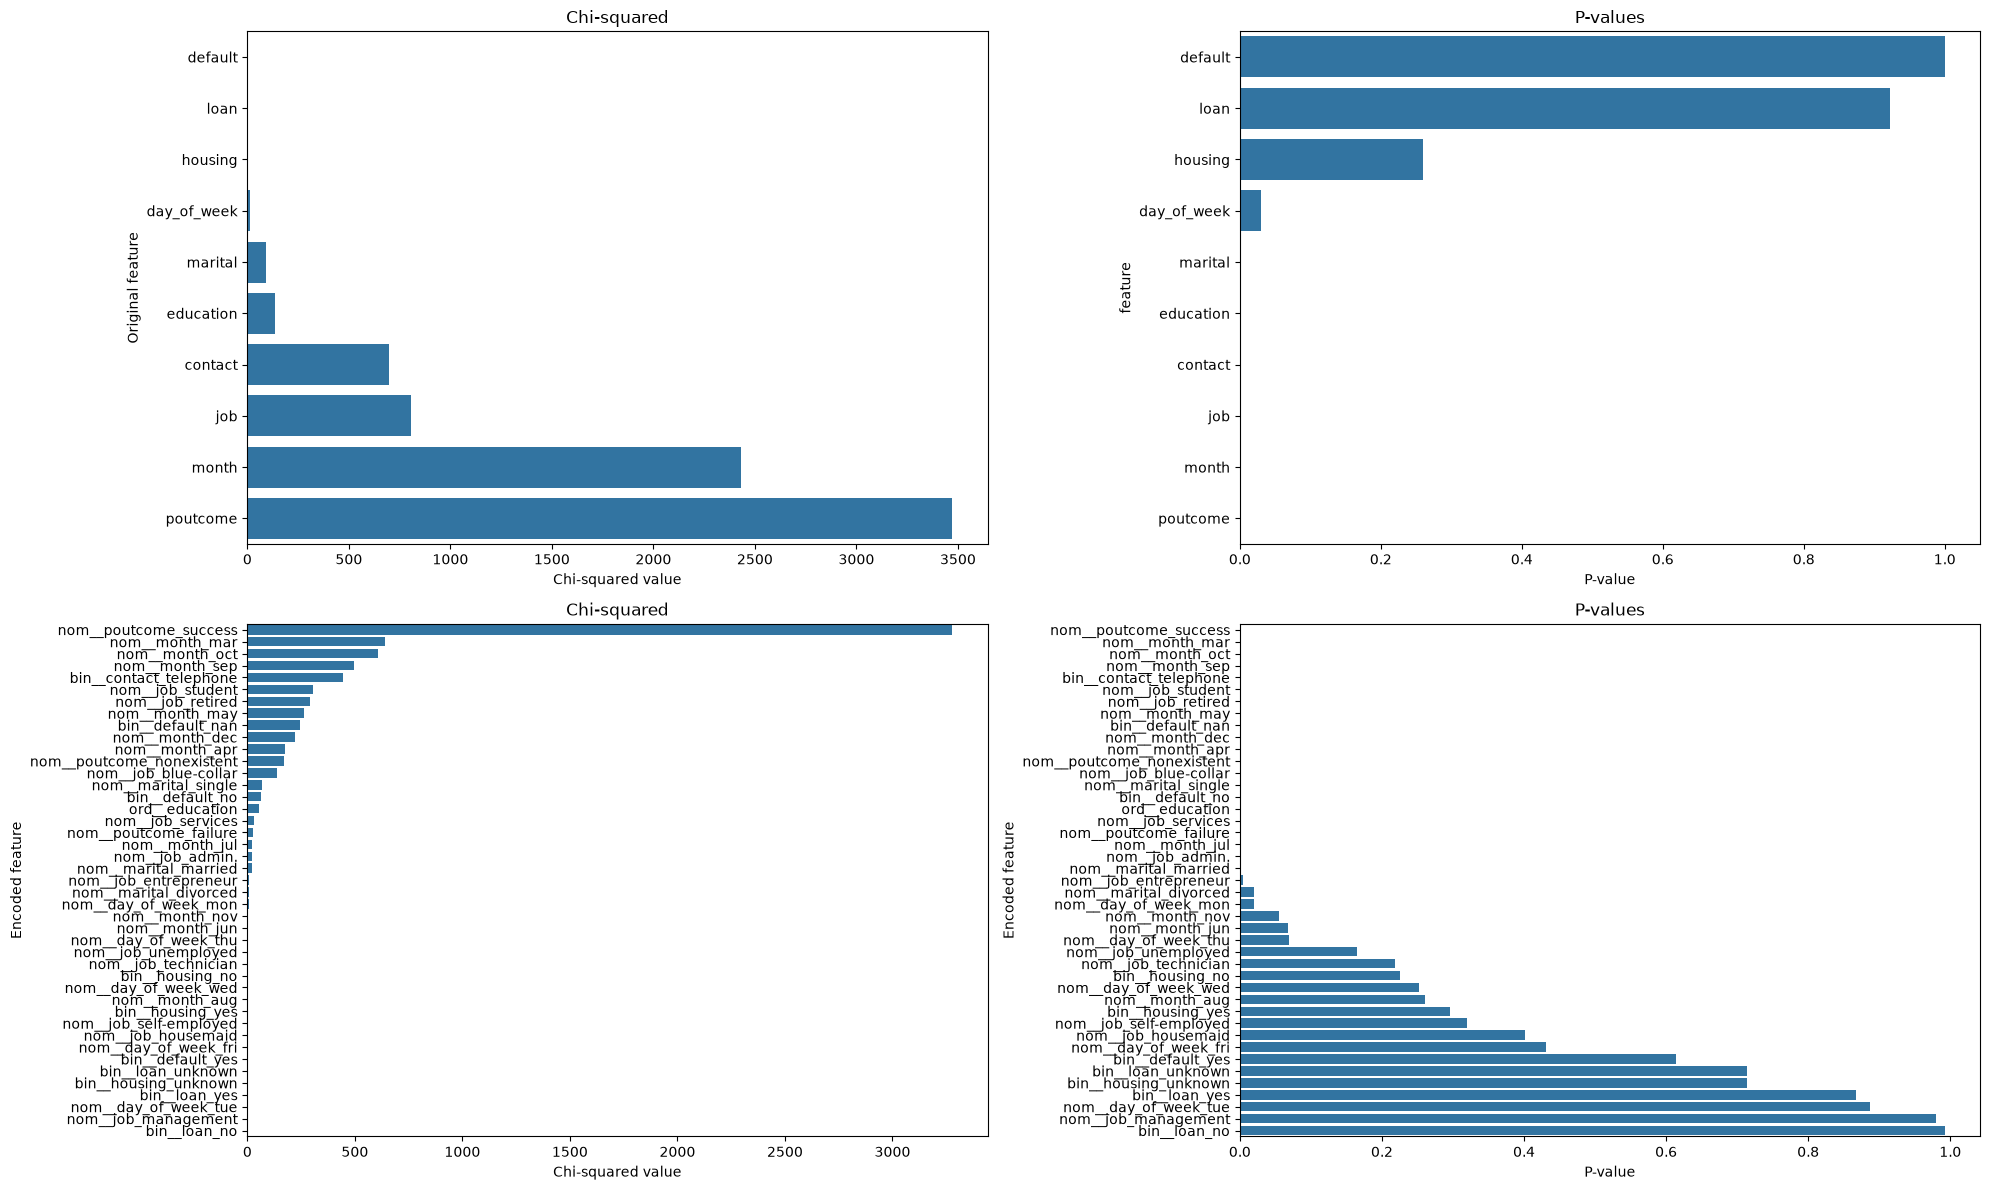

[{'feature': 'education', 'chi2': np.float64(134.397765223087), 'p': np.float64(1.522348133550894e-26)}, {'feature': 'contact', 'chi2': np.float64(695.955851765982), 'p': np.float64(2.2653451501936362e-153)}, {'feature': 'housing', 'chi2': np.float64(2.6951891684793177), 'p': np.float64(0.25986459184158006)}, {'feature': 'loan', 'chi2': np.float64(0.16283402165121186), 'p': np.float64(0.921809206864658)}, {'feature': 'default', 'chi2': np.float64(0.0), 'p': np.float64(1.0)}, {'feature': 'job', 'chi2': np.float64(804.8934115239085), 'p': np.float64(1.8304840215876017e-166)}, {'feature': 'marital', 'chi2': np.float64(92.72793571565148), 'p': np.float64(7.317868485394994e-21)}, {'feature': 'poutcome', 'chi2': np.float64(3472.036012209419), 'p': np.float64(0.0)}, {'feature': 'month', 'chi2': np.float64(2430.8933373236537), 'p': np.float64(0.0)}, {'feature': 'day_of_week', 'chi2': np.float64(10.660416755662943), 'p': np.float64(0.03065758354792011)}]


In [38]:
from sklearn.feature_selection import VarianceThreshold
from sklearn.feature_selection import chi2
from scipy.stats import chi2_contingency

# use original feature names
x_original = X_trainOriginal.reset_index(drop=True).copy()
y_original = pd.Series(y_train).reset_index(drop=True)

# Original feature names
groupedResults = []

for feature in ordinalCols + binaryCols + nominalCols:
    # Treat missing values as a category for this test
    xValues = x_original[feature].astype(str)

    # chiTable needed for unencoded values
    chiTable = pd.crosstab(xValues, y_original)

    chi_val, p_val, dof, expectedFreq = chi2_contingency(chiTable)

    groupedResults.append({
        'feature': feature,
        'chi2': chi_val,
        'p': p_val,
    })
chiDf = pd.DataFrame(groupedResults)

# Encoded feature names

encScores, encP = chi2(X_trainEncoded, y_trainEncoded)
encResults = pd.DataFrame({
        'feature': strProcessedNames,
        'chi2': encScores,
        'p': encP,
    })

encPlot = encResults.sort_values("chi2", ascending=False)
# Plotting original
fig, axes = plt.subplots(2, 2, figsize=(20, 12))

plotChi = chiDf.sort_values('chi2', ascending=True)

sns.barplot(data=plotChi, x='chi2', y='feature', ax=axes[0,0])
axes[0,0].set_title('Chi-squared')
axes[0,0].set_xlabel('Chi-squared value')
axes[0,0].set_ylabel('Original feature')

sns.barplot(data=plotChi, x='p', y='feature', ax=axes[0,1])
axes[0,1].set_title('P-values')
axes[0,1].set_xlabel('P-value')
axes[0,1].set_ylabel('feature')

# Plotting encoded
sns.barplot(data=encPlot, x='chi2', y='feature', ax=axes[1,0])
axes[1,0].set_title('Chi-squared')
axes[1,0].set_xlabel('Chi-squared value')
axes[1,0].set_ylabel('Encoded feature')

sns.barplot(data=encPlot, x='p', y='feature', ax=axes[1,1])
axes[1,1].set_title('P-values')
axes[1,1].set_xlabel('P-value')
axes[1,1].set_ylabel('Encoded feature')

plt.tight_layout()
plt.show()


print(groupedResults)

**Interpretation:** Chi squared shows the association between the feature and y, this was assessed using only the train set, for chi-squared a higher value means a higher association to y and as seen in the graph poutcome has the highest association, month is second with both showing a strong association, job and contact are next with a moderate association, education, marital and default both show a weak association and day of the week, loan and housing are the weakest with them being close to zero.

A small p value (>0.05) means the data would be unlikely if the feature had no effect and a large p value (>0.05) means the data shows that the feature has no effect, so this graph shows us poutcome, job, month, contact, education and marital are all useful features. loan, housing and day_of_week all have p-values above 0.05 so they seem to have no effect on the target which is consistent with the ch-squared results. (only done on categorical features)

Many of the encoded features have little association with the target.

### 7.3 Mutual Information

Calucating mutual information for original categorical features and encoded feature names.

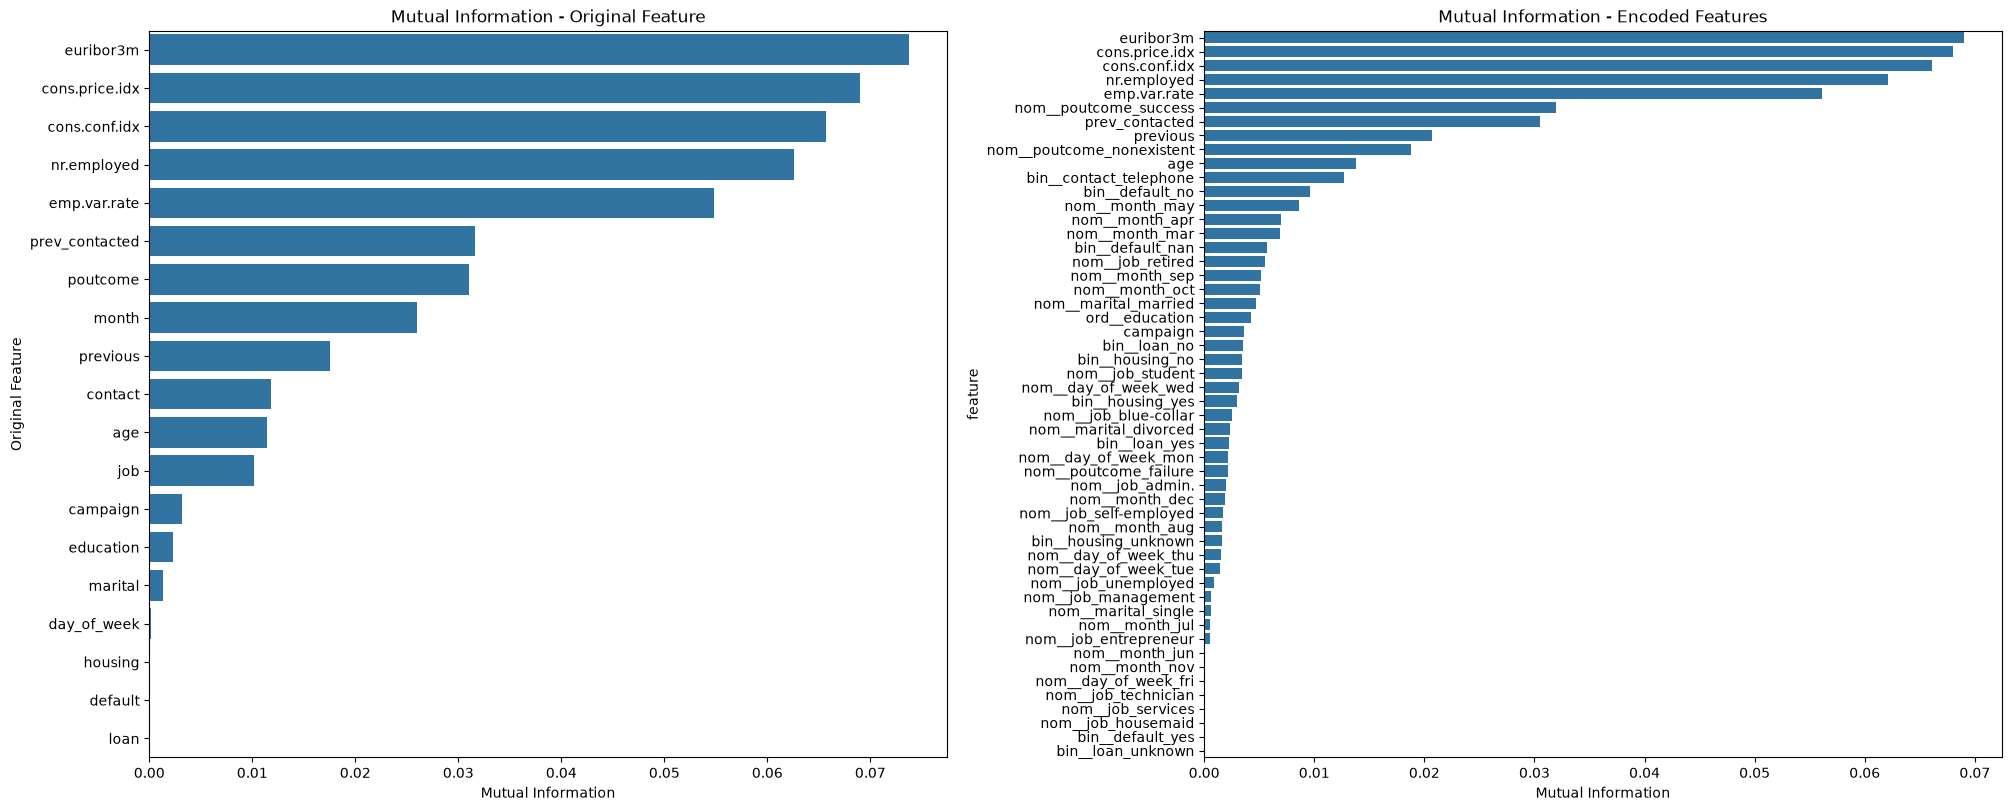

In [39]:
from sklearn.feature_selection import mutual_info_classif

# Assigning original feature names (instead of encoded names)
originalCols = ordinalCols + binaryCols + nominalCols
X_original = X_trainOriginal[originalCols].copy()

# Original features
# strFeatures without duration
strFeatures = ordinalCols + binaryCols + nominalCols
numFeatures = X_trainOriginal.select_dtypes(include="number").columns.tolist()
miVals = []

x_originalImputed = SimpleImputer(strategy="most_frequent").fit_transform(X_original)

# Change to df
x_originalImputed = pd.DataFrame(
    x_originalImputed,
    columns=originalCols,
    index=X_original.index
)
for feature in originalCols:
    # Encode categories as integers for mutual information
    encodedFeature = OrdinalEncoder().fit_transform(
        x_originalImputed[[feature]].astype(str)
    ).ravel()

    miCat = mutual_info_classif(
        encodedFeature.reshape(-1, 1),
        y_trainEncoded,
        # treats features as nominal even though they are ordinally encoded
        discrete_features=True
    )[0]
    miVals.append(miCat)

miCatEnc = mutual_info_classif(
    X_trainEncoded,
    y_trainEncoded
)
miNum = mutual_info_classif(X_train[numFeatures], y_train)
miVals.extend(miNum)

miDf = pd.DataFrame({
    'feature': strFeatures + numFeatures,
    'mutualInfo': miVals
}).sort_values('mutualInfo')


# Encoded features
miCatEnc = mutual_info_classif(
    X_trainAll,
    y_trainEncoded
)

miDfEnc = pd.DataFrame({
    'feature': list(strProcessedNames) + list(numFeatures),
    'mutualInfo': miCatEnc
}).sort_values('mutualInfo')


fig, axes = plt.subplots(1, 2, figsize=(20, 8), constrained_layout=True)

sns.barplot(data=miDf, x='mutualInfo', y='feature', ax=axes[0])
axes[0].set_title('Mutual Information - Original Feature')
axes[0].set_xlabel('Mutual Information')
axes[0].set_ylabel('Original Feature')
axes[0].invert_yaxis()

sns.barplot(data=miDfEnc, x='mutualInfo', y='feature', ax=axes[1])
axes[1].set_xlabel('Mutual Information')
axes[1].set_title('Mutual Information - Encoded Features')
axes[1].invert_yaxis()

plt.show()

**Interperetation:** This mutual information graph supports the results from chi-squared with poutcome having the strongest association and day_of_week, housing and loan being the weakest, apart from the categorical features, all numeric features have a moderate to high importance compared to other features so removing them most likely will not be needed. And as seen previously, many of the encoded features have little or no relevance.

We also see that prev_contacted and poutcome have the same mutual information, likely because they represent similar information.

### 7.3 Backward Elimination


In [40]:
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

lr = LogisticRegression(max_iter=1000, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

sfs = SequentialFeatureSelector(
    lr,
    direction='backward',
    scoring="roc_auc",
    tol=-0.0001,
    cv=cv,
    n_jobs=-1
                                )
sfs.fit(X_trainAll, y_trainEncoded)

# transform X_train with sfs to find chosen features
X_train_selected = sfs.transform(X_trainAll)

print("Selected feature indices:", sfs.get_support(indices=True))
print("Number of selected features:", X_train_selected.shape[1], "of", X_trainEncoded.shape[1])


Selected feature indices: [ 1 11 12 14 18 20 21 24 28 29 31 32 34 35 36 37 42 44 45 46 47 49 51]
Number of selected features: 23 of 43


**Interpretation:** Using SequentialFeatureSelector with the "backward" direction applies backward selection which starts with the full list of features and drops those that reduce the model accuracy by 0.0001 (tol) or lower to make as little impact as possible as removing a feature usually makes some loss so if it was set to positive it would remove one feature then stop, cv is the amount of cross validation folds, for example 3 would split the data into 3 equal pieces.

In [41]:
# same order as the columns of X_trainEncoded
namesAll = list(strProcessedNames) + [f"num__{c}" for c in numFeatures]
mask = sfs.get_support()

# Find the original feature for each encoded feature (since all encoded stat with __)
def originalCol(name, cat_cols):
    name = name.split("__", 1)[1]
    # longest names first
    for col in sorted(cat_cols, key=len, reverse=True):
        if name.startswith(col + "_"):
            return col
    return name

summary = pd.DataFrame({
    "feature": namesAll,
    "original": [originalCol(n, list(strFeatures)) for n in namesAll],
    "kept": mask,
})

by_col = (summary.groupby("original")["kept"]
          .agg(kept="sum", total="count")
          .sort_values("kept", ascending=False))
print(by_col)

                kept  total
original                   
month              8     10
job                6     11
campaign           1      1
prev_contacted     1      1
previous           1      1
cons.price.idx     1      1
contact            1      1
euribor3m          1      1
marital            1      3
day_of_week        1      5
emp.var.rate       1      1
cons.conf.idx      0      1
age                0      1
default            0      3
education          0      1
housing            0      3
loan               0      3
poutcome           0      3
nr.employed        0      1


**Interpretation:** 12 out of 19 original features has at least one encoded feature kept, the ones that were dropped entirely were:
- age
- default
- education
- housing
- loan
- poutcome
- nr.employed
- cons.conf.idx

Partially kept features
- job: 6 of 11
- day_of_week: 1 of 5
- month: 8 of 10 (strongest partially kept feature)
- marital: 1 of 3

euribor3m, emp.var.rate and nr.employed are correlated features so this is most likely why some of them were dropped. previous, poutcome and prev_contacted are also correlated which may be why poutcome was dropped. cons.conf.idx is weakly correlated with other features so this may be a reason it was dropped.

Overall 23 of 43 columns were kept with backward elimination, month, prev_contacted, euribor3m were kept while poutcome, and nr.employe (cons.conf.inx) were dropped mostly because they were correlated with other features (euribor3m with emp.var.rate, nr.employed, cons.price.idx and poutcome with prev_contacted and previous)

### 7.4 Gini Importance

In [42]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

rf = RandomForestClassifier()
rf.fit(X_trainAll, y_trainEncoded)


importances = rf.feature_importances_

# Grouping results by original feature names to see total importance (using function from backward elim)
imp = pd.DataFrame({
    "feature": namesAll,
    "importance": rf.feature_importances_,
})

original
age               0.170454
euribor3m         0.115179
job               0.102387
campaign          0.084925
day_of_week       0.073026
education         0.064935
nr.employed       0.056448
housing           0.043136
marital           0.042400
poutcome          0.040916
loan              0.030518
month             0.029802
cons.conf.idx     0.026371
emp.var.rate      0.026187
prev_contacted    0.026059
cons.price.idx    0.021674
default           0.016271
contact           0.014683
previous          0.014629
Name: importance, dtype: float64


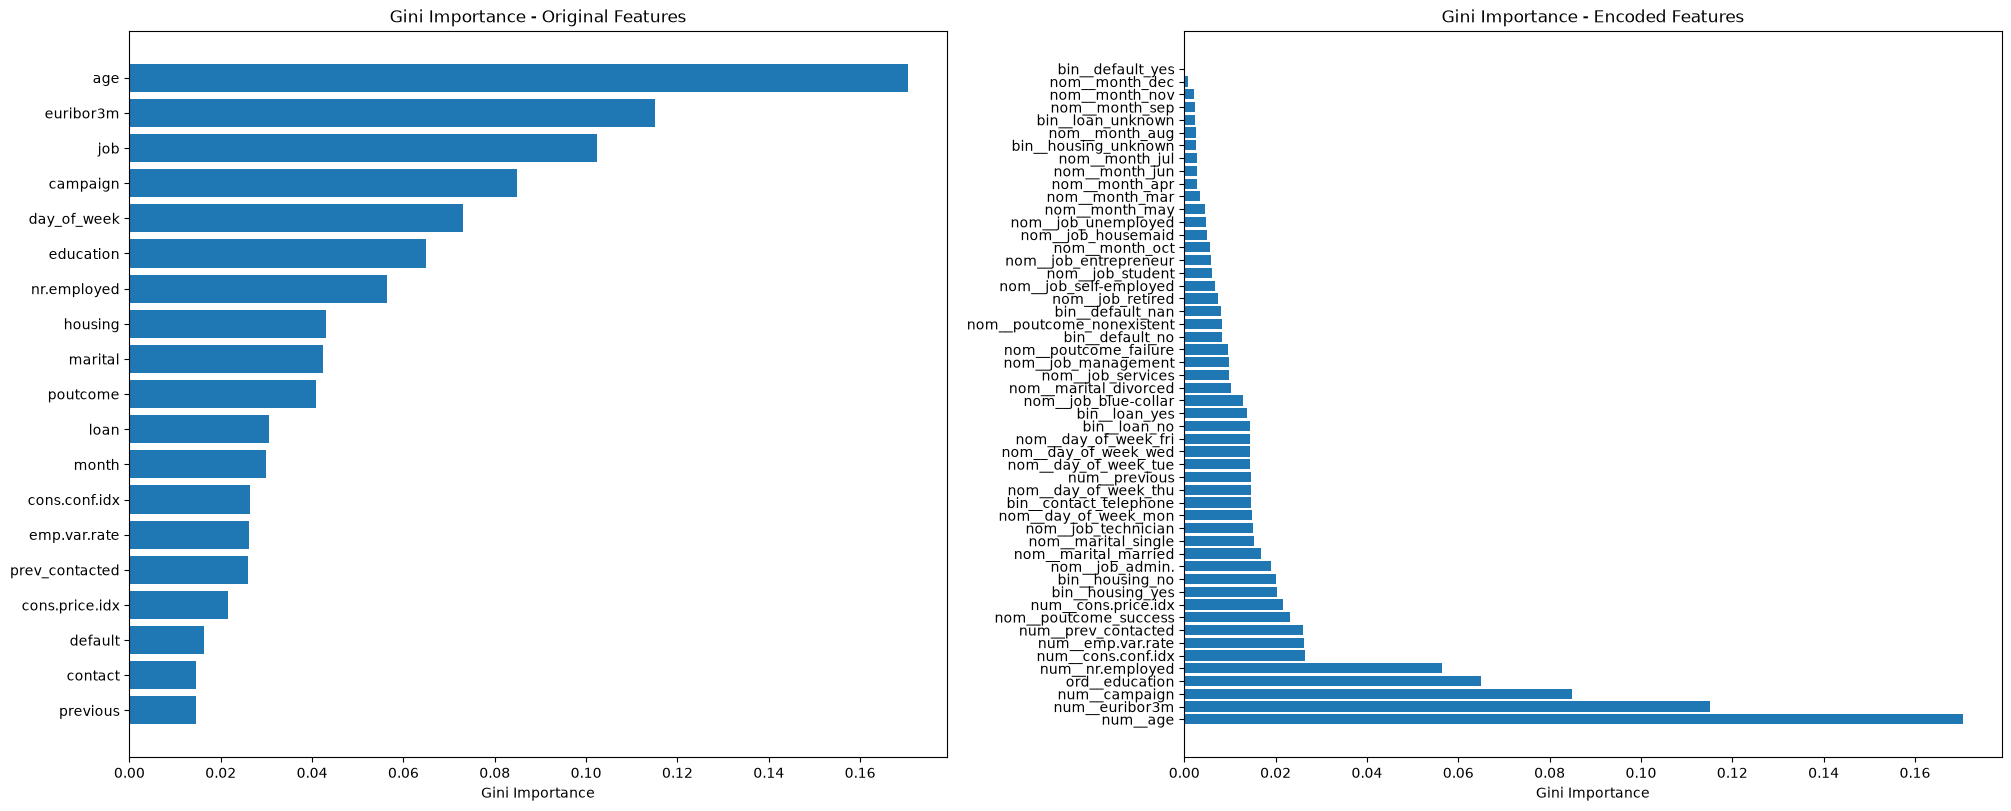

In [43]:
imp["original"] = [originalCol(n, originalCols) for n in imp["feature"]]

# group results with original column
byCol = (imp.groupby("original")["importance"]
          .sum()
          .sort_values(ascending=False))

# Sorting results
impSorted = imp.sort_values("importance")
print(byCol)

# plotting the sorted importance and its feature (original)
fig, axes = plt.subplots(1,2, figsize =(20,8), constrained_layout=True)
axes[0].barh(byCol.index, byCol.values)
axes[0].set_xlabel('Gini Importance')
axes[0].set_title('Gini Importance - Original Features')
axes[0].invert_yaxis()

# plotting the sorted importance and its feature (encoded + numeric)
axes[1].barh(impSorted["feature"], impSorted["importance"])
axes[1].set_xlabel('Gini Importance')
axes[1].set_title('Gini Importance - Encoded Features')
axes[1].invert_yaxis()

plt.show()

**Interpretation:** age, euribor3m, campaign and job are the top features, though Gini importance seems to have bias for features with many unique values as in the encoded feature graph most of the job values only show moderate importance, this is also seen in age and euribor3m which have many unique values so continuous features are favoured here.

poutcome's result dropped compared to the chi-squared and mutual information graph which shows the ranking depends on which features are available, poutcome overlaps with prev_contacted and previous so this could also be another reason.
default still has low importance however housing and day_of_week are higher than previous feature selection methods, day_of_week's result is most likely caused by the many values it contains as previously stated.

Unlike mutual information, campaign has a high value here which shows that it may have an association with the target. 

Euribor3m, nr.employed and emp.var.rate are correlated so they split credit as seen in some of these features having low importance.

default is near-constant and has low importance so this is a strong candidate for a feature to drop, emp.var.rate, nr.employed and cons.price.idx also are candidates since they correlate with euribor3m and have low importance.

## 8. Numeric Pipeline

In [44]:
from sklearn.preprocessing import FunctionTransformer

# clean copies of the split (same rows as before, but no log yet)
X_train_raw, X_test_raw, _, _ = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# log step: applies log1p to campaign only
def log_campaign(data):
    data = data.copy()
    data["campaign"] = np.log1p(data["campaign"])
    return data

log_step = FunctionTransformer(log_campaign)

print(X_train_raw["campaign"].max())                                 # should be 56 (raw)
print(log_step.fit_transform(X_train_raw[num_cols])["campaign"].max())  # should be about 4.04

56
4.04305126783455


In [45]:
from sklearn.pipeline import Pipeline

# numeric pipeline: log -> scale -> PCA (4 components)
num_pipe = Pipeline([
    ("log", log_step),
    ("scale", StandardScaler()),
    ("pca", PCA(n_components=4)),
])

X_train_np = num_pipe.fit_transform(X_train_raw[num_cols])  # learn on train
X_test_np = num_pipe.transform(X_test_raw[num_cols])        # apply to test

print(X_train_np.shape, X_test_np.shape)
print(round(num_pipe.named_steps["pca"].explained_variance_ratio_.sum() * 100, 1))

(32940, 4) (8236, 4)
83.7


In [46]:
# same result as the manual steps in section 6?
print(np.allclose(X_train_np, X_train_pca), np.allclose(X_test_np, X_test_pca))

True True


**Interpretation:** The numeric pipeline joins the log transform on campaign, StandardScaler and PCA (4 components) into one object. It is fitted on the training set only and then applied to the test set, so no test information leaks into the preprocessing. It gives the same result as the manual steps in Section 6 (83.7% variance, identical values), so the preprocessing is reproducible and can be reused in CA2. It will be combined with the categorical pipeline in a ColumnTransformer.

## 9. Full Pipeline (numeric + categorical)

In [47]:
# copies for the full pipeline
Xtr = X_train_raw.copy()
Xte = X_test_raw.copy()
ytr = y_train.copy()
yte = y_test.copy()
# "unknown" -> empty (NaN), so the imputer can fill it (housing and loan keep "unknown")
unk_cols = ["job", "marital", "education", "default"]
Xtr[unk_cols] = Xtr[unk_cols].replace("unknown", np.nan)
Xte[unk_cols] = Xte[unk_cols].replace("unknown", np.nan)

print(Xtr.shape, Xte.shape)
print(Xtr[unk_cols].isnull().sum())

(32940, 19) (8236, 19)
job           267
marital        68
education    1389
default      6857
dtype: int64


In [48]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectFpr, SelectPercentile, SequentialFeatureSelector
from sklearn.feature_selection import chi2, mutual_info_classif
from functools import partial
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
mi = partial(mutual_info_classif, random_state=42)

ordinalCols = ['education']
binaryCols = ['contact', 'housing', 'loan']
nominalCols = ['job', 'marital', 'poutcome', 'month', 'day_of_week']
strFeatures = ordinalCols + binaryCols + nominalCols

edu_order = [
    'illiterate', 'basic.4y', 'basic.6y', 'basic.9y',
    'high.school', 'professional.course', 'university.degree'
]

# Categorical features - impute missing values, encode, and select features
cat_pipe = Pipeline([
    ("encoding", ColumnTransformer([
        ("ord", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("enc", OrdinalEncoder(categories=[edu_order]))
        ]), ordinalCols),
        ("bin", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("enc", OneHotEncoder(drop="if_binary", handle_unknown="ignore"))
        ]), binaryCols),
        ("nom", Pipeline([
            ("imp", SimpleImputer(strategy="most_frequent")),
            ("enc", OneHotEncoder(drop="first", handle_unknown="ignore"))
        ]), nominalCols)
    ])),

    ("mi", SelectPercentile(mi, percentile=75)),
    # fitted from feature selection
    ("be", sfs)
])

# Complete pipeline
full_pipe = ColumnTransformer([
    # yours: log -> scale -> PCA
    ("num", num_pipe, num_cols),
    # already 0/1, keep as it is
    ("prev", "passthrough", ["prev_contacted"]),
    # Cillian's: fill empty with most common, then encode
    ("cat", cat_pipe, strFeatures)
])   # default is not listed, so it is dropped


# Fit and transform
X_train_ready = full_pipe.fit_transform(Xtr, y_train)
X_test_ready = full_pipe.transform(Xte)
print(X_train_ready.shape, X_test_ready.shape)

(32940, 21) (8236, 21)


**Interpretation:** The full pipeline combines the numeric pipeline (log on campaign, scaling, PCA with 4 components) with the categorical pipeline (most-frequent imputation of "unknown", ordinal encoding for education, one-hot encoding for the rest). prev_contacted is passed through unchanged and default is dropped because it is near-constant. It is fitted on the training set only and applied to the test set, so there is no leakage. The result is 21 numeric columns for 32,940 training rows and 8,236 test rows, ready for modelling in CA2.